# Retail Sales and Customer Purchasing Analysis Using Exploratory Data Analysis and Data Visualization

- **Mini project** — Department of Artificial Intelligence and Data Science
- **Student:** [Your Name] · **Register No.:** [Register Number]
- **Guide:** [Guide Name] · **Academic year:** [YYYY–YYYY]
- **Tools:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn (optional PCA only)
- **Dataset:** Sample Superstore — fictional US retailer, orders from 2014 to 2017

### How to run this notebook

**Google Colab (recommended)**
- Open colab.research.google.com → *File → Upload notebook* → choose this `.ipynb`.
- *Runtime → Run all*.
- When Section 5 shows a **Choose Files** button, select your Superstore CSV or Excel file.
- Section 20 creates a ZIP of the whole project folder and downloads it.

**VS Code / Jupyter (local)**
- Keep the project folder structure and put the dataset at `Retail_Sales_Analysis/data/original_dataset.csv`.
- Install libraries: `pip install -r requirements.txt`.
- Open `notebooks/retail_sales_analysis.ipynb` and click *Run All*.

## Section 1 — Project Title and Introduction

- **What retail analytics is:** turning raw sales transactions into answers about products, customers, regions and time.
- **Why it matters:** retailers make daily decisions on stock, prices, discounts and promotions; data shows which of those decisions make or lose money.
- **What this project does:** cleans a retail transaction dataset and explores it with statistics and charts — one variable at a time, two at a time, then many together.
- **Real-world use:**
  - Category managers use the same category/sub-category profit views to decide what to stock or drop.
  - Pricing teams use discount-vs-profit analysis to set discount caps.
  - Supply-chain teams use monthly trends to plan inventory before peak months.
- **Scope note:** this is Exploratory Data Analysis (EDA) — it describes and explains patterns; it does not build a prediction model.

## Section 2 — Business Problem Statement

- A retailer records thousands of transactions (sales, quantity, discount, profit) but raw rows do not show:
  - which categories and products actually generate profit,
  - which ones lose money,
  - how sales change across months and years,
  - how discounts relate to profitability,
  - how customer segments and regions differ.
- **Problem:** use EDA and data visualization to convert the transaction data into clear, evidence-based answers that support decisions on inventory, pricing, discounts and product selection.

## Section 3 — Objectives and Scope

**Objectives**
- Load, inspect, clean and validate a retail sales dataset, documenting every cleaning decision.
- Describe the distributions of Sales, Profit, Quantity and Discount.
- Compare sales and profit across categories, sub-categories, regions and customer segments.
- Analyze monthly and yearly sales trends.
- Measure relationships between variables (Pearson and Spearman correlation).
- Identify top-selling, most profitable and loss-making products.
- Produce business recommendations backed by the data.

**Scope**
- In scope: data cleaning, univariate / bivariate / multivariate EDA, 12+ charts, business metrics, insights.
- Optional demonstrations: 3D scatter plot and PCA (they cannot break the rest of the notebook).
- Out of scope: prediction models, forecasting, clustering, dashboards (listed as future enhancements).

**Syllabus mapping**

| Unit | Topic | Where in this notebook |
|---|---|---|
| Unit 1 | Exploratory Data Analysis | Sections 5–9 (loading, inspection, cleaning, slicing, filtering, grouping) |
| Unit 2 | Visualizing using Matplotlib | Line, scatter, histogram, density, legends, subplots, annotations, error bars, 3D (Sections 8–17) |
| Unit 3 | Univariate analysis | Section 10 (statistics, skewness, IQR outliers, box plots, pie, frequency tables) |
| Unit 4 | Bivariate analysis | Section 11 (scatter, Pearson, Spearman, grouped/stacked bars, box, violin) |
| Unit 5 | Multivariate analysis | Section 12 (heatmaps, pair plot, region × category, PCA) and Sections 13–17 |

## Section 4 — Import Libraries and Project Setup

- Imports every library used in the notebook (all are pre-installed in Google Colab).
- Detects whether the notebook runs in Colab or locally and creates the project folders.

In [1]:
# ---- Standard library ----
import shutil
import warnings
from pathlib import Path

# ---- Data handling ----
import numpy as np
import pandas as pd

# ---- Visualization ----
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

# ---- Statistics for correlation p-values (pre-installed in Colab) ----
try:
    from scipy import stats
    SCIPY_AVAILABLE = True
except ImportError:
    SCIPY_AVAILABLE = False

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.2f}".format)

RANDOM_STATE = 42          # fixed seed -> samples and jitter are reproducible
np.random.seed(RANDOM_STATE)

# ---- Detect the environment ----
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    PROJECT_DIR = Path("/content/Retail_Sales_Analysis")
else:
    cwd = Path.cwd()
    PROJECT_DIR = cwd.parent if cwd.name == "notebooks" else cwd

DATA_DIR = PROJECT_DIR / "data"
CHART_DIR = PROJECT_DIR / "outputs" / "charts"
TABLE_DIR = PROJECT_DIR / "outputs" / "summary_tables"
for folder in [DATA_DIR, CHART_DIR, TABLE_DIR, PROJECT_DIR / "notebooks",
               PROJECT_DIR / "report", PROJECT_DIR / "presentation"]:
    folder.mkdir(parents=True, exist_ok=True)

print("Running in Colab :", IN_COLAB)
print("Project folder   :", PROJECT_DIR.resolve())
print("SciPy available  :", SCIPY_AVAILABLE)
print("pandas", pd.__version__, "| numpy", np.__version__, "| seaborn", sns.__version__)

Running in Colab : False
Project folder   : /home/claude/Retail_Sales_Analysis
SciPy available  : True
pandas 3.0.5 | numpy 2.5.3 | seaborn 0.13.2


In [2]:
# ---- One consistent, colour-blind-safe chart style for every figure ----
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
YELLOW, MAGENTA, GREEN, VIOLET = "#eda100", "#e87ba4", "#008300", "#6250d6"
CATEGORICAL_SLOTS = [BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED]
NEUTRAL, INK, INK_2, GRID = "#f0efec", "#0b0b0b", "#52514e", "#e1e0d9"

plt.rcParams.update({
    "figure.figsize": (9, 5), "figure.dpi": 100, "font.size": 10,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.labelsize": 11,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK_2, "ytick.color": INK_2, "legend.frameon": False,
})

# Diverging map: red = loss, light gray = zero, blue = profit
DIVERGING_CMAP = LinearSegmentedColormap.from_list("loss_zero_profit", [RED, NEUTRAL, BLUE])
SEQUENTIAL_CMAP = LinearSegmentedColormap.from_list("light_to_dark_blue", ["#cde2fb", BLUE, "#0d366b"])

# Dollar axis formatter: 12000 -> $12K
def money_short(value, decimals=0):
    """12345 -> '$12K', -1234.5 -> '-$1.2K' (sign before the dollar symbol)."""
    sign = "-" if value < 0 else ""
    value = abs(value)
    if value >= 1000:
        return f"{sign}${value / 1000:,.{decimals}f}K"
    return f"{sign}${value:,.0f}"


MONEY_FMT = mticker.FuncFormatter(lambda x, _: money_short(x))


def save_chart(fig, name):
    """Save a figure as PNG inside outputs/charts/."""
    fig.savefig(CHART_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    print(f"Chart saved -> outputs/charts/{name}.png")


def save_table(table, name, index=True):
    """Save a summary table as CSV inside outputs/summary_tables/."""
    table.to_csv(TABLE_DIR / f"{name}.csv", index=index)
    print(f"Table saved -> outputs/summary_tables/{name}.csv")


print("Chart style and helper functions ready.")

Chart style and helper functions ready.


**What the code does**
- `pathlib.Path` builds folder paths that work on Windows, macOS, Linux and Colab.
- `RANDOM_STATE` fixes the random seed so every rerun gives the same sample (reproducibility).
- The colour palette is colour-blind safe and fixed: each category keeps the same colour in every chart.
- `save_chart()` and `save_table()` export every chart (PNG) and table (CSV) into the project folder.

**How to read the output**
- Check that the project folder path is printed and no `ImportError` appears.
- If a library is missing locally, run `pip install -r requirements.txt`.

## Section 5 — Upload or Load the Dataset

- **Colab:** the first run shows a *Choose Files* button; the uploaded file is copied to `data/original_dataset.csv` (or `.xlsx`).
- **Local:** the notebook reads `data/original_dataset.csv` directly.
- The original file is **never modified**; all cleaning happens on a copy in memory.

In [3]:
SUPPORTED_EXTENSIONS = (".csv", ".xlsx", ".xls")


def find_original_file():
    """Return data/original_dataset.<ext> if it already exists."""
    for ext in SUPPORTED_EXTENSIONS:
        candidate = DATA_DIR / f"original_dataset{ext}"
        if candidate.exists():
            return candidate
    return None


original_file = find_original_file()

if original_file is None and IN_COLAB:
    from google.colab import files
    print("Select your Superstore CSV or Excel file...")
    uploaded = files.upload()
    if not uploaded:
        raise ValueError("No file uploaded. Re-run this cell and select the dataset.")
    uploaded_name = next(iter(uploaded))
    extension = Path(uploaded_name).suffix.lower()
    if extension not in SUPPORTED_EXTENSIONS:
        raise ValueError(f"'{uploaded_name}' is not a CSV/Excel file. Upload .csv, .xlsx or .xls.")
    original_file = DATA_DIR / f"original_dataset{extension}"
    shutil.copy(uploaded_name, original_file)      # untouched copy of the raw file

if original_file is None:
    raise FileNotFoundError(
        f"Dataset not found. Put your file at {DATA_DIR / 'original_dataset.csv'} "
        "(or .xlsx) and run this cell again.")


def load_dataset(path):
    """Read a CSV (trying common text encodings) or an Excel file."""
    if path.suffix.lower() in (".xlsx", ".xls"):
        return pd.read_excel(path), "excel"
    for encoding in ("utf-8", "cp1252", "latin-1"):
        try:
            return pd.read_csv(path, encoding=encoding), encoding
        except UnicodeDecodeError:
            continue
    raise ValueError("Could not decode the CSV file with utf-8, cp1252 or latin-1.")


df_raw, used_encoding = load_dataset(original_file)   # df_raw stays untouched
if df_raw.empty:
    raise ValueError("The dataset has no rows - check that you uploaded the correct file.")

print(f"Loaded {original_file.name} using encoding: {used_encoding}")
print(f"Rows: {len(df_raw):,} | Columns: {df_raw.shape[1]}")

Loaded original_dataset.csv using encoding: cp1252
Rows: 9,994 | Columns: 21


**What the code does**
- `find_original_file()` checks whether the dataset was already saved, so re-running the notebook does not ask for the upload again.
- `load_dataset()` tries `utf-8` first, then `cp1252` and `latin-1`.
  - The Kaggle Superstore CSV contains special characters in some product names, so the default `utf-8` raises `UnicodeDecodeError`.
- `df_raw` is kept exactly as read; the cleaned version is created later as `df`.

**How to read the output**
- The printed encoding tells you which one worked.
- The row and column counts are the dataset size *before* cleaning.

**Result in this run**
- UTF-8 failed and the file loaded with `cp1252` encoding.
- Size before cleaning: **9,994 rows × 21 columns**.

## Section 6 — Inspect the Dataset (Unit 1)

- Looks at the first and last rows, column names, data types, missing values, duplicates and summary statistics.
- Nothing is changed here — inspection comes before cleaning.

In [4]:
print("Shape (rows, columns):", df_raw.shape)
print("\nFirst 5 rows:")
display(df_raw.head())
print("Last 3 rows:")
display(df_raw.tail(3))
print("Column names and data types:")
df_raw.info()

Shape (rows, columns): (9994, 21)

First 5 rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91
1,2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58
2,3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87
3,4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.58,5,0.45,-383.03
4,5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.37,2,0.20,2.52


Last 3 rows:


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
9991,9992,CA-2017-121258,2/26/2017,03-03-2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627,West,TEC-PH-10003645,Technology,Phones,Aastra 57i VoIP phone,258.58,2,0.20,19.39
9992,9993,CA-2017-121258,2/26/2017,03-03-2017,Standard Class,DB-13060,Dave Brooks,Consumer,United States,Costa Mesa,California,92627,West,OFF-PA-10004041,Office Supplies,Paper,"It's Hot Message Books with Stickers, 2 3/4"" x 5""",29.60,4,0.00,13.32
9993,9994,CA-2017-119914,05-04-2017,05-09-2017,Second Class,CC-12220,Chris Cortes,Consumer,United States,Westminster,California,92683,West,OFF-AP-10002684,Office Supplies,Appliances,"Acco 7-Outlet Masterpiece Power Center, Wihtou...",243.16,2,0.00,72.95


Column names and data types:
<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   flo

In [5]:
inspection = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "missing_count": df_raw.isnull().sum(),
    "missing_pct": (df_raw.isnull().mean() * 100).round(2),
    "unique_values": df_raw.nunique(),
})
print("Column inspection:")
display(inspection)
print("Exact duplicate rows:", df_raw.duplicated().sum())

print("\nNumerical summary (raw data):")
display(df_raw.describe().T)
print("Text-column summary (raw data):")
display(df_raw.describe(exclude="number").T)

Column inspection:


,dtype,missing_count,missing_pct,unique_values
Row ID,int64,0,0.00,9994
Order ID,str,0,0.00,5009
Order Date,str,0,0.00,1237
Ship Date,str,0,0.00,1334
Ship Mode,str,0,0.00,4
Customer ID,str,0,0.00,793
Customer Name,str,0,0.00,793
Segment,str,0,0.00,3
Country,str,0,0.00,1
City,str,0,0.00,531


Exact duplicate rows: 0

Numerical summary (raw data):


,count,mean,std,min,25%,50%,75%,max
Row ID,"9,994.00","4,997.50","2,885.16",1.00,"2,499.25","4,997.50","7,495.75","9,994.00"
Postal Code,"9,994.00","55,190.38","32,063.69","1,040.00","23,223.00","56,430.50","90,008.00","99,301.00"
Sales,"9,994.00",229.86,623.25,0.44,17.28,54.49,209.94,"22,638.48"
Quantity,"9,994.00",3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,"9,994.00",0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,"9,994.00",28.66,234.26,"-6,599.98",1.73,8.67,29.36,"8,399.98"


Text-column summary (raw data):


,count,unique,top,freq
Order ID,9994,5009,CA-2017-100111,14
Order Date,9994,1237,09-05-2016,38
Ship Date,9994,1334,12/16/2015,35
Ship Mode,9994,4,Standard Class,5968
Customer ID,9994,793,WB-21850,37
Customer Name,9994,793,William Brown,37
Segment,9994,3,Consumer,5191
Country,9994,1,United States,9994
City,9994,531,New York City,915
State,9994,49,California,2001


**What the code does**
- `info()` shows each column's data type and non-null count.
- The inspection table combines data type, missing count, missing %, and number of unique values per column.
- `describe()` gives count, mean, std, min, quartiles and max for numerical columns; `describe(exclude="number")` gives counts, unique values and the most frequent value for text columns.

**How to read the output**
- **Dates stored as text** (`object`/`str` type) must be converted before time analysis.
- **Missing values > 0** need a decision (drop, keep, or fill with a justified value — never automatically 0).
- **Unique values** that look too high for a small category list (e.g., Category with 4 values instead of 3) signal inconsistent labels.

**Result in this run**
- All 21 columns have **0 missing values** and there are **0 exact duplicate rows**.
- `Order Date` and `Ship Date` are stored as text, so they must be converted before trend analysis.
- `Category` has **4 unique values** although Superstore has only 3 categories → an inconsistent label (fixed in 7.2).
- Sales: mean **$229.86** vs median **$54.49** → strongly right-skewed.
- Profit ranges from **−$6,599.98 to $8,399.98** → large gains and large losses exist.
- The data covers 5,009 orders, 793 customers, 1,850 product names, 17 sub-categories, 4 regions and 3 segments.

## Section 7 — Clean and Validate the Data (Unit 1)

Cleaning steps, in order:
1. Standardise column names (handles other dataset versions).
2. Trim spaces and fix inconsistent category labels.
3. Convert dates safely and verify the date format.
4. Convert numbers and check for invalid or infinite values.
5. Handle duplicates.
6. Handle missing values.
7. Validate value ranges (negative sales, discounts outside 0–1, ship date before order date).
8. Create new features (year, month, margin, discount band).

Every decision is recorded in `cleaning_log`, which is saved as a CSV in Section 20.

### 7.1 Standardise column names and check required columns

In [6]:
df = df_raw.copy()                     # all cleaning happens on this copy
df.columns = df.columns.str.strip()

COLUMN_ALIASES = {
    "orderid": "Order ID", "orderdate": "Order Date", "shipdate": "Ship Date",
    "shipmode": "Ship Mode", "customerid": "Customer ID", "customername": "Customer Name",
    "segment": "Segment", "customersegment": "Segment", "region": "Region",
    "productid": "Product ID", "productname": "Product Name",
    "category": "Category", "productcategory": "Category",
    "subcategory": "Sub-Category", "productsubcategory": "Sub-Category",
    "sales": "Sales", "profit": "Profit", "discount": "Discount",
    "quantity": "Quantity", "qty": "Quantity", "orderquantity": "Quantity",
}


def normalize_key(name):
    """'Sub-Category' -> 'subcategory', 'order_date' -> 'orderdate'."""
    return "".join(ch for ch in str(name).lower() if ch.isalnum())


rename_map = {}
for col in df.columns:
    standard = COLUMN_ALIASES.get(normalize_key(col))
    if standard and standard != col and standard not in df.columns:
        rename_map[col] = standard
df = df.rename(columns=rename_map)
print("Columns renamed:", rename_map if rename_map else "none needed")

REQUIRED = ["Order Date", "Category", "Sales", "Quantity", "Discount", "Profit"]
OPTIONAL = ["Order ID", "Ship Date", "Customer ID", "Segment", "Region",
            "Sub-Category", "Product Name", "Ship Mode"]

missing_required = [c for c in REQUIRED if c not in df.columns]
if missing_required:
    raise ValueError(
        f"Required columns missing: {missing_required}.\n"
        "Fix: find the matching column in your file (for example 'Qty' for Quantity) and add "
        "its lowercase, no-space name to COLUMN_ALIASES above, then re-run.")

available_optional = [c for c in OPTIONAL if c in df.columns]
print("All required columns present:", REQUIRED)
print("Optional columns available  :", available_optional)
print("Optional columns missing    :", [c for c in OPTIONAL if c not in df.columns] or "none")


def has(col):
    """True if an optional column exists - used before every optional analysis."""
    return col in df.columns


cleaning_log = []


def log_step(step, rows_affected, decision):
    cleaning_log.append({"step": step, "rows_affected": int(rows_affected), "decision": decision})

Columns renamed: none needed
All required columns present: ['Order Date', 'Category', 'Sales', 'Quantity', 'Discount', 'Profit']
Optional columns available  : ['Order ID', 'Ship Date', 'Customer ID', 'Segment', 'Region', 'Sub-Category', 'Product Name', 'Ship Mode']
Optional columns missing    : none


### 7.2 Trim spaces and fix inconsistent category labels

In [7]:
text_cols = [c for c in ["Ship Mode", "Segment", "Region", "Category", "Sub-Category",
                         "Product Name", "Customer Name", "State", "City"] if has(c)]
cells_trimmed = 0
for col in text_cols:
    original = df[col].astype("string")
    df[col] = original.str.strip()
    cells_trimmed += int((original != df[col]).fillna(False).sum())
log_step("Trim spaces in text columns", cells_trimmed,
         "Removed leading/trailing spaces so labels such as 'West ' and 'West' form one group")
print("Text cells with extra spaces fixed:", cells_trimmed)

print("\nCategory labels before fixing:")
display(df["Category"].value_counts().to_frame("rows"))

# In Superstore, every Sub-Category belongs to exactly one Category.
# A row whose Category disagrees with its Sub-Category's usual Category is an inconsistent label.
if has("Sub-Category"):
    usual_category = df.groupby("Sub-Category")["Category"].agg(lambda s: s.mode().iloc[0])
    expected = df["Sub-Category"].map(usual_category)
    inconsistent = df["Category"].notna() & expected.notna() & (df["Category"] != expected)
    if inconsistent.any():
        print("Rows with an inconsistent Category label:")
        display(df.loc[inconsistent, [c for c in ["Order ID", "Product Name", "Sub-Category", "Category"] if has(c)]])
        df.loc[inconsistent, "Category"] = expected[inconsistent]
    log_step("Fix inconsistent Category labels", inconsistent.sum(),
             "Replaced with the Category that the row's Sub-Category always belongs to")
    print("Inconsistent Category labels fixed:", int(inconsistent.sum()))

for col in ["Category", "Segment", "Region", "Ship Mode"]:
    if has(col):
        print(f"{col:9s}: {sorted(df[col].dropna().unique().tolist())}")

Text cells with extra spaces fixed: 16

Category labels before fixing:


,rows
Category,
Office Supplies,6026
Furniture,2121
Technology,1846
C,1


Rows with an inconsistent Category label:


,Order ID,Product Name,Sub-Category,Category
19,CA-2014-143336,Cisco SPA 501G IP Phone,Phones,C


Inconsistent Category labels fixed: 1
Category : ['Furniture', 'Office Supplies', 'Technology']
Segment  : ['Consumer', 'Corporate', 'Home Office']
Region   : ['Central', 'East', 'South', 'West']
Ship Mode: ['First Class', 'Same Day', 'Second Class', 'Standard Class']


### 7.3 Convert dates safely and verify the format

In [8]:
# The Superstore file uses US month-first dates, sometimes written two ways:
#   '4/15/2017'  (month/day/year)   and   '11-08-2016'  (month-day-year)
DATE_FORMATS = ["%m/%d/%Y", "%m-%d-%Y", "%Y-%m-%d", "%m/%d/%y"]


def parse_dates_month_first(series):
    """Convert a text date column that may mix '/' and '-' styles (all month-first)."""
    if pd.api.types.is_datetime64_any_dtype(series):
        return series                       # Excel files already contain real dates
    text = series.astype("string").str.strip()
    result = None
    for fmt in DATE_FORMATS:
        attempt = pd.to_datetime(text, format=fmt, errors="coerce")
        result = attempt if result is None else result.fillna(attempt)
    return result


raw_order_text = df["Order Date"].astype("string")
print("Order dates written with '/':", int(raw_order_text.str.contains("/").sum()))
print("Order dates written with '-':", int(raw_order_text.str.contains("-").sum()))

raw_dates = df[["Order Date"] + (["Ship Date"] if has("Ship Date") else [])].copy()
df["Order Date"] = parse_dates_month_first(df["Order Date"])
failed = df["Order Date"].isna().sum()
log_step("Convert Order Date to datetime", failed,
         "Parsed '/' and '-' styles as month-first; values that cannot be parsed become NaT (reviewed in 7.6)")
print("Order dates that could not be parsed:", int(failed))

if has("Ship Date"):
    df["Ship Date"] = parse_dates_month_first(df["Ship Date"])
    df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days

    # Verification: what if the '-' dates were day-first instead?
    if not pd.api.types.is_datetime64_any_dtype(raw_dates["Order Date"]):
        def parse_dash_as_day_first(series):
            text = series.astype("string").str.strip()
            dash_day_first = pd.to_datetime(text, format="%d-%m-%Y", errors="coerce")
            return dash_day_first.fillna(pd.to_datetime(text, format="%m/%d/%Y", errors="coerce"))

        alt_days = (parse_dash_as_day_first(raw_dates["Ship Date"])
                    - parse_dash_as_day_first(raw_dates["Order Date"])).dt.days
        print("\nVerification using shipping time (Ship Date - Order Date):")
        print(f"  month-first reading: {df['Ship Days'].min():.0f} to {df['Ship Days'].max():.0f} days, "
              f"negative = {int((df['Ship Days'] < 0).sum())}")
        print(f"  day-first reading  : {alt_days.min():.0f} to {alt_days.max():.0f} days, "
              f"negative = {int((alt_days < 0).sum())}")

print("\nOrder date range:", df["Order Date"].min().date(), "to", df["Order Date"].max().date())

Order dates written with '/': 5952
Order dates written with '-': 4042


Order dates that could not be parsed:

 0



Verification using shipping time (Ship Date - Order Date):
  month-first reading: 0 to 7 days, negative = 0
  day-first reading  : -322 to 214 days, negative = 1708

Order date range: 2014-01-03 to 2017-12-30


**Why this check matters**
- `pd.to_datetime()` without a format guesses each value; mixed styles such as `11-08-2016` and `4/15/2017` can be silently read with the day and month swapped.
- A shipment cannot leave before it is ordered, so the shipping-time range is used as **evidence** for the correct format: the reading that gives no negative shipping days is the correct one.

**Result in this run**
- 5,952 order dates use `/` and 4,042 use `-`.
- Reading both styles as **month-first** gives shipping times of **0–7 days** with no negative values.
- Reading the `-` dates as day-first would give **1,708 orders shipped before they were placed** (−322 to 214 days), which is impossible.
- So month-first is confirmed. Orders run from **3 Jan 2014 to 30 Dec 2017** (4 full years).

**Real-world use**
- Date mix-ups are a common silent error in company data pipelines.
- Checking a business rule (ship date ≥ order date) is a standard data-quality test before any reporting.

### 7.4 Convert numerical columns and check invalid / infinite values

In [9]:
NUMERIC_COLS = ["Sales", "Quantity", "Discount", "Profit"]
for col in NUMERIC_COLS:
    missing_before = df[col].isna().sum()
    if not pd.api.types.is_numeric_dtype(df[col]):
        # remove $ , % and spaces, then convert; invalid text becomes NaN (never 0)
        cleaned_text = df[col].astype("string").str.replace(r"[$,%\s]", "", regex=True)
        df[col] = pd.to_numeric(cleaned_text, errors="coerce")
    invalid = df[col].isna().sum() - missing_before
    infinite = int(np.isinf(df[col]).sum())
    df[col] = df[col].replace([np.inf, -np.inf], np.nan)
    log_step(f"Convert {col} to numeric", invalid + infinite,
             "Invalid text or infinite values set to NaN (not 0) and handled in 7.6")
    print(f"{col:9s} dtype={str(df[col].dtype):8s} invalid->NaN={invalid}  infinite={infinite}")

# Some dataset versions store discount as 20 instead of 0.20
if df["Discount"].max() > 1 and df["Discount"].max() <= 100:
    df["Discount"] = df["Discount"] / 100
    log_step("Rescale Discount", len(df), "Discount stored as percent (0-100) -> converted to 0-1")
    print("Discount converted from percent to fraction.")

Sales     dtype=float64  invalid->NaN=0  infinite=0
Quantity  dtype=int64    invalid->NaN=0  infinite=0
Discount  dtype=float64  invalid->NaN=0  infinite=0
Profit    dtype=float64  invalid->NaN=0  infinite=0


### 7.5 Handle duplicate records

In [10]:
exact_duplicates = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
log_step("Remove exact duplicate rows", exact_duplicates,
         "Rows identical in every column are copies -> removed")
print("Exact duplicate rows removed:", exact_duplicates)

# Rows identical in everything except the Row ID need a judgement call
id_cols = [c for c in ["Row ID"] if c in df.columns]
if id_cols:
    same_content = df.drop(columns=id_cols).duplicated(keep=False)
    extra_copies = int(df.drop(columns=id_cols).duplicated().sum())
    print("Rows identical except for Row ID:", int(same_content.sum()))
    if same_content.any():
        display(df.loc[same_content, [c for c in ["Row ID", "Order ID", "Product Name",
                                                    "Sales", "Quantity", "Profit"] if has(c)]])
    log_step("Check duplicates ignoring Row ID", extra_copies,
             "Kept: different Row IDs, so they may be two genuine line items; "
             "no evidence of an error (effect on totals is negligible)")

Exact duplicate rows removed: 0


Rows identical except for Row ID: 2


,Row ID,Order ID,Product Name,Sales,Quantity,Profit
3405,3406,US-2014-150119,Global Leather Highback Executive Chair with P...,281.37,2,-12.06
3406,3407,US-2014-150119,Global Leather Highback Executive Chair with P...,281.37,2,-12.06


### 7.6 Handle missing values

In [11]:
missing_essential = df[REQUIRED].isna().any(axis=1)
print("Rows missing an essential value:", int(missing_essential.sum()))
if missing_essential.any():
    display(df.loc[missing_essential].head(10))
df = df.loc[~missing_essential].copy()
log_step("Drop rows missing essential values", missing_essential.sum(),
         "Rows without date, category, sales, quantity, discount or profit cannot be analysed; "
         "they are removed, not filled with 0")

optional_missing = df[available_optional].isna().sum()
print("Missing values in optional columns:")
print(optional_missing[optional_missing > 0] if optional_missing.any() else "none")

Rows missing an essential value: 0
Missing values in optional columns:
none


### 7.7 Validate value ranges

In [12]:
checks = {
    "Sales <= 0": int((df["Sales"] <= 0).sum()),
    "Quantity <= 0": int((df["Quantity"] <= 0).sum()),
    "Discount outside 0-1": int((~df["Discount"].between(0, 1)).sum()),
    "Profit < 0 (loss-making rows)": int((df["Profit"] < 0).sum()),
}
if has("Ship Days"):
    checks["Ship Date before Order Date"] = int((df["Ship Days"] < 0).sum())
validation = pd.Series(checks, name="rows").to_frame()
display(validation)

log_step("Validate value ranges", checks["Profit < 0 (loss-making rows)"],
         "Negative profit KEPT: these are real loss-making sales and are central to the analysis")

,rows
Sales <= 0,0
Quantity <= 0,0
Discount outside 0-1,0
Profit < 0 (loss-making rows),1871
Ship Date before Order Date,0


**Decisions**
- **Negative profit is not an error** — it is a sale made at a loss. Deleting these rows would hide the most important business problem.
- Rows with `Sales <= 0`, `Quantity <= 0` or a discount outside 0–1 would be inspected individually (returns or data errors) before any decision.

**Result in this run**
- **16 product names** had trailing spaces → trimmed.
- **1 row** had Category `C` (a Cisco IP phone in Sub-Category *Phones*) → corrected to *Technology*.
- No invalid text in numeric columns, no infinite values, no missing values, no exact duplicates.
- **2 rows** (Row IDs 3406 and 3407) are identical except for Row ID → kept and documented, because they could be two genuine line items of the same order.
- **1,871 rows (18.7%)** have negative profit → kept.
- No sales ≤ 0, quantity ≤ 0, discounts outside 0–1, or ship-before-order dates.
- Cleaned dataset: **9,994 rows × 30 columns** (21 original + 9 new features).

### 7.8 Create new features

In [13]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["Month Name"] = df["Order Date"].dt.strftime("%b")
df["Quarter"] = df["Order Date"].dt.quarter
df["Year-Month"] = df["Order Date"].dt.to_period("M").astype(str)
df["Profit Margin (%)"] = np.where(df["Sales"] != 0, df["Profit"] / df["Sales"] * 100, np.nan)
df["Is Loss"] = df["Profit"] < 0
df["Discount Band"] = pd.cut(df["Discount"], bins=[-0.001, 0, 0.2, 0.4, 1.0],
                             labels=["0%", "1-20%", "21-40%", "Above 40%"])

# Fixed colour per category (colour follows the category in every chart)
CATEGORY_ORDER = sorted(df["Category"].unique())
CATEGORY_COLORS = {cat: CATEGORICAL_SLOTS[i] for i, cat in enumerate(CATEGORY_ORDER[:8])}

log_step("Create features", len(df),
         "Added Year, Month, Month Name, Quarter, Year-Month, Profit Margin (%), Is Loss, Discount Band")

cleaning_log_df = pd.DataFrame(cleaning_log)
print(f"Raw shape: {df_raw.shape} -> cleaned shape: {df.shape}")
display(cleaning_log_df)
display(df.head(3))

Raw shape: (9994, 21) -> cleaned shape: (9994, 30)


,step,rows_affected,decision
0,Trim spaces in text columns,16,Removed leading/trailing spaces so labels such...
1,Fix inconsistent Category labels,1,Replaced with the Category that the row's Sub-...
2,Convert Order Date to datetime,0,Parsed '/' and '-' styles as month-first; valu...
3,Convert Sales to numeric,0,Invalid text or infinite values set to NaN (no...
4,Convert Quantity to numeric,0,Invalid text or infinite values set to NaN (no...
5,Convert Discount to numeric,0,Invalid text or infinite values set to NaN (no...
6,Convert Profit to numeric,0,Invalid text or infinite values set to NaN (no...
7,Remove exact duplicate rows,0,Rows identical in every column are copies -> r...
8,Check duplicates ignoring Row ID,1,"Kept: different Row IDs, so they may be two ge..."
9,Drop rows missing essential values,0,"Rows without date, category, sales, quantity, ..."


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Ship Days,Year,Month,Month Name,Quarter,Year-Month,Profit Margin (%),Is Loss,Discount Band
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.00,41.91,3,2016,11,Nov,4,2016-11,16.00,False,0%
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.00,219.58,3,2016,11,Nov,4,2016-11,30.00,False,0%
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.00,6.87,4,2016,6,Jun,2,2016-06,47.00,False,0%


**What the code does**
- `Profit Margin (%)` = Profit ÷ Sales × 100 for each row (`NaN` when Sales is 0 to avoid division by zero).
- `Discount Band` groups discounts into 4 levels for easier comparison.
- `cleaning_log_df` documents every decision — copy it into the *Methodology* chapter of the report.

**How to read the output**
- Compare raw and cleaned shapes: the difference in rows should equal the rows removed in the log.

## Section 8 — Exploratory Data Analysis: Slicing, Filtering and Grouping (Unit 1)

- **Slicing** selects rows/columns by position or label.
- **Filtering** keeps rows that satisfy a condition.
- **Grouping** (`groupby`) summarises the data per category, region or segment.

In [14]:
# ---- Slicing ----
print("Rows 10-14, selected columns (label-based .loc):")
display(df.loc[df.index[10:15], ["Order Date", "Category", "Sales", "Profit"]])
print("First 3 rows, first 4 columns (position-based .iloc):")
display(df.iloc[:3, :4])

# ---- Filtering ----
high_value = df[df["Sales"] > 1000]
print(f"Transactions with Sales > $1,000: {len(high_value):,} "
      f"({len(high_value) / len(df):.1%} of rows, {high_value['Sales'].sum() / df['Sales'].sum():.1%} of sales)")

heavy_discount_losses = df[(df["Discount"] >= 0.4) & (df["Profit"] < 0)]
print(f"Loss-making transactions with discount >= 40%: {len(heavy_discount_losses):,}")

if has("Region"):
    latest_year = int(df["Year"].max())
    west_latest = df.query("Region == 'West' and Year == @latest_year")
    print(f"West region orders in {latest_year}: {len(west_latest):,} rows, sales ${west_latest['Sales'].sum():,.0f}")

Rows 10-14, selected columns (label-based .loc):


,Order Date,Category,Sales,Profit
10,2014-06-09,Furniture,"1,706.18",85.31
11,2014-06-09,Technology,911.42,68.36
12,2017-04-15,Office Supplies,15.55,5.44
13,2016-12-05,Office Supplies,407.98,132.59
14,2015-11-22,Office Supplies,68.81,-123.86


First 3 rows, first 4 columns (position-based .iloc):


,Row ID,Order ID,Order Date,Ship Date
0,1,CA-2016-152156,2016-11-08,2016-11-11
1,2,CA-2016-152156,2016-11-08,2016-11-11
2,3,CA-2016-138688,2016-06-12,2016-06-16


Transactions with Sales > $1,000: 468 (4.7% of rows, 43.1% of sales)
Loss-making transactions with discount >= 40%: 1,113
West region orders in 2017: 1,095 rows, sales $250,128


In [15]:
# ---- Grouping and aggregation ----
category_summary = (
    df.groupby("Category")
      .agg(Transactions=("Sales", "size"),
           Total_Sales=("Sales", "sum"),
           Total_Profit=("Profit", "sum"),
           Units=("Quantity", "sum"),
           Avg_Discount=("Discount", "mean"))
      .assign(Profit_Margin_pct=lambda t: t["Total_Profit"] / t["Total_Sales"] * 100,
              Sales_Share_pct=lambda t: t["Total_Sales"] / t["Total_Sales"].sum() * 100)
      .sort_values("Total_Sales", ascending=False)
)
display(category_summary)
save_table(category_summary, "category_summary")

,Transactions,Total_Sales,Total_Profit,Units,Avg_Discount,Profit_Margin_pct,Sales_Share_pct
Category,,,,,,,
Technology,1847,"836,154.03","145,454.95",6939,0.13,17.40,36.40
Furniture,2121,"741,999.80","18,451.27",8028,0.17,2.49,32.30
Office Supplies,6026,"719,047.03","122,490.80",22906,0.16,17.04,31.30


Table saved -> outputs/summary_tables/category_summary.csv


Chart saved -> outputs/charts/01_category_sales.png


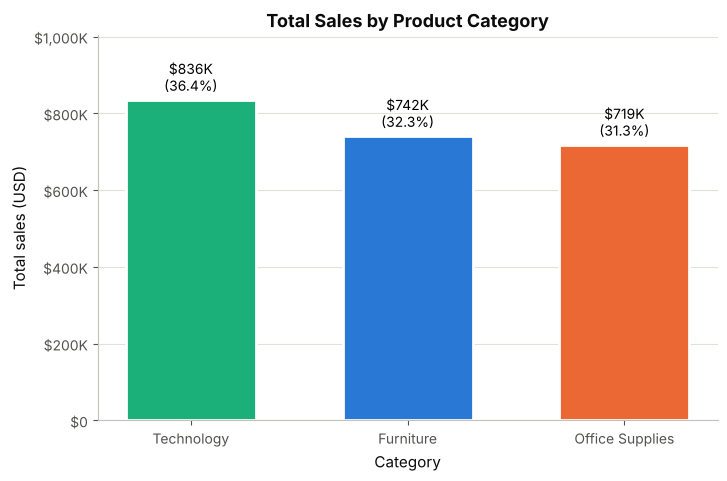

Chart saved -> outputs/charts/02_category_profit.png


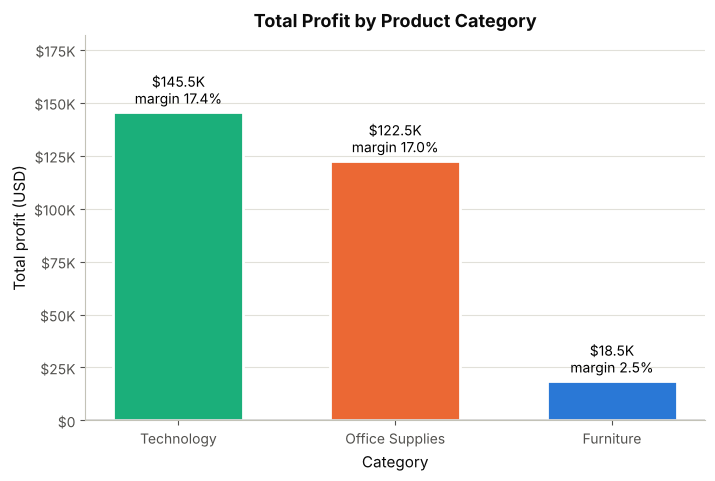

In [16]:
# Chart 1 - Category-wise total sales (bar chart with value annotations)
fig, ax = plt.subplots(figsize=(8, 5))
sales_by_cat = category_summary["Total_Sales"]
bars = ax.bar(sales_by_cat.index, sales_by_cat.values,
              color=[CATEGORY_COLORS[c] for c in sales_by_cat.index], width=0.6, edgecolor="white", linewidth=2)
ax.bar_label(bars, labels=[f"${v / 1000:,.0f}K\n({s:.1f}%)" for v, s in
                           zip(sales_by_cat.values, category_summary["Sales_Share_pct"])], padding=4)
ax.set_title("Total Sales by Product Category")
ax.set_xlabel("Category")
ax.set_ylabel("Total sales (USD)")
ax.yaxis.set_major_formatter(MONEY_FMT)
ax.set_ylim(0, sales_by_cat.max() * 1.2)
save_chart(fig, "01_category_sales")
plt.show()

# Chart 2 - Category-wise total profit
fig, ax = plt.subplots(figsize=(8, 5))
profit_by_cat = category_summary["Total_Profit"].sort_values(ascending=False)
bars = ax.bar(profit_by_cat.index, profit_by_cat.values,
              color=[CATEGORY_COLORS[c] for c in profit_by_cat.index], width=0.6, edgecolor="white", linewidth=2)
margins = category_summary.loc[profit_by_cat.index, "Profit_Margin_pct"]
ax.bar_label(bars, labels=[f"${v / 1000:,.1f}K\nmargin {m:.1f}%" for v, m in zip(profit_by_cat.values, margins)],
             padding=4)
ax.axhline(0, color=INK_2, linewidth=1)
ax.set_title("Total Profit by Product Category")
ax.set_xlabel("Category")
ax.set_ylabel("Total profit (USD)")
ax.yaxis.set_major_formatter(MONEY_FMT)
ax.set_ylim(min(0, profit_by_cat.min() * 1.2), profit_by_cat.max() * 1.25)
save_chart(fig, "02_category_profit")
plt.show()

**What the code does**
- `.loc` slices by labels; `.iloc` slices by position.
- Boolean filters such as `df[df["Sales"] > 1000]` keep rows meeting a condition; `query()` does the same with readable text.
- `groupby().agg()` computes totals per category; `assign()` adds margin and share columns.
- `bar_label()` writes the value on each bar (Unit 2 text annotation).

**How to read the output**
- Compare the **sales** ranking with the **profit** ranking: a category can sell a lot but earn little.

**Result in this run**
- Only **468 transactions (4.7%)** exceed $1,000, but they make up **43.1% of sales** → revenue is concentrated in a few large transactions.
- **1,113 loss-making rows** carry a discount of 40% or more.
- **Sales:** Technology leads with **$836,154 (36.4%)**, but all three categories are close (31–36%).
- **Profit:** the ranking changes sharply:
  - Technology **$145,455** (17.4% margin)
  - Office Supplies **$122,491** (17.0% margin)
  - Furniture only **$18,451** (2.5% margin)
- Furniture sells almost as much as the other categories but keeps only about 2.5 cents of profit per dollar of sales.

## Section 9 — Key Business Metrics

- Calculates the headline numbers used in the report, each with a clear definition.
- **Transaction-level** metrics use rows; **order-level** metrics use unique `Order ID`s.

In [17]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
kpis = [
    ("Transactions (rows)", f"{len(df):,}", "Number of order lines after cleaning"),
    ("Total recorded sales", f"${total_sales:,.2f}", "Sum of Sales"),
    ("Total recorded profit", f"${total_profit:,.2f}", "Sum of Profit (losses included)"),
    ("Overall profit margin", f"{total_profit / total_sales * 100:.2f}%", "Total Profit / Total Sales x 100"),
    ("Average row profit margin", f"{df['Profit Margin (%)'].mean():.2f}%",
     "Mean of row-level margins (each row weighted equally)"),
    ("Total units recorded", f"{int(df['Quantity'].sum()):,}",
     "Sum of Quantity across transactions (not unique products)"),
    ("Average transaction value", f"${df['Sales'].mean():,.2f}", "Total Sales / number of rows"),
    ("Loss-making transactions", f"{df['Is Loss'].mean() * 100:.1f}%", "Share of rows with Profit < 0"),
]
if has("Order ID"):
    n_orders = df["Order ID"].nunique()
    kpis += [("Unique orders", f"{n_orders:,}", "Distinct Order IDs"),
             ("Average order value (AOV)", f"${total_sales / n_orders:,.2f}", "Total Sales / unique orders"),
             ("Average lines per order", f"{len(df) / n_orders:.2f}", "Rows / unique orders")]
if has("Customer ID"):
    kpis.append(("Unique customers", f"{df['Customer ID'].nunique():,}", "Distinct Customer IDs"))
if has("Product Name"):
    kpis.append(("Unique product names", f"{df['Product Name'].nunique():,}", "Distinct Product Names"))
kpis.append(("Date range", f"{df['Order Date'].min():%d %b %Y} to {df['Order Date'].max():%d %b %Y}",
             "First and last order date"))

kpi_table = pd.DataFrame(kpis, columns=["Metric", "Value", "Definition"])
display(kpi_table)
save_table(kpi_table, "key_metrics", index=False)

,Metric,Value,Definition
0,Transactions (rows),"9,994",Number of order lines after cleaning
1,Total recorded sales,"$2,297,200.86",Sum of Sales
2,Total recorded profit,"$286,397.02",Sum of Profit (losses included)
3,Overall profit margin,12.47%,Total Profit / Total Sales x 100
4,Average row profit margin,12.03%,Mean of row-level margins (each row weighted e...
5,Total units recorded,"37,873",Sum of Quantity across transactions (not uniqu...
6,Average transaction value,$229.86,Total Sales / number of rows
7,Loss-making transactions,18.7%,Share of rows with Profit < 0
8,Unique orders,"5,009",Distinct Order IDs
9,Average order value (AOV),$458.61,Total Sales / unique orders


Table saved -> outputs/summary_tables/key_metrics.csv


**What the code does**
- Builds a table of metric, value and definition so every number in the report has a clear meaning.

**How to read the output**
- **Overall margin vs average row margin:** the overall margin weights big sales more; the row average treats a $2 sale and a $2,000 sale equally. A big gap means small transactions behave differently from large ones.
- **AOV vs average transaction value:** one order can contain several lines, so AOV is larger.

**Result in this run**
- Total sales **$2,297,200.86**; total profit **$286,397.02**; overall margin **12.47%**.
- **5,009 orders** → average order value **$458.61**. An order averages 2 lines, so the average transaction is $229.86.
- **18.7%** of transactions lose money.
- **37,873 units** were recorded across all transactions.
- The overall margin (12.47%) and the average row margin (12.03%) are close, so small and large transactions have similar average margins.

## Section 10 — Univariate Analysis (Unit 3)

- Studies **one variable at a time**: Sales, Profit, Quantity, Discount, and categorical columns.
- Tools: mean, median, standard deviation, quartiles, skewness, IQR outliers, histograms, density plots, box plots, bar charts, pie chart, frequency tables.

### 10.1 Summary statistics and skewness

In [18]:
VARIABLES = ["Sales", "Profit", "Quantity", "Discount"]
univariate_stats = pd.DataFrame({
    "mean": df[VARIABLES].mean(),
    "median": df[VARIABLES].median(),
    "std": df[VARIABLES].std(),
    "min": df[VARIABLES].min(),
    "Q1 (25%)": df[VARIABLES].quantile(0.25),
    "Q3 (75%)": df[VARIABLES].quantile(0.75),
    "max": df[VARIABLES].max(),
    "skewness": df[VARIABLES].skew(),
    "kurtosis": df[VARIABLES].kurt(),
}).round(3)
display(univariate_stats)
save_table(univariate_stats, "univariate_statistics")

,mean,median,std,min,Q1 (25%),Q3 (75%),max,skewness,kurtosis
Sales,229.86,54.49,623.25,0.44,17.28,209.94,"22,638.48",12.97,305.31
Profit,28.66,8.67,234.26,"-6,599.98",1.73,29.36,"8,399.98",7.56,397.19
Quantity,3.79,3.00,2.23,1.00,2.00,5.00,14.00,1.28,1.99
Discount,0.16,0.20,0.21,0.00,0.00,0.20,0.80,1.68,2.41


Table saved -> outputs/summary_tables/univariate_statistics.csv


### 10.2 Outlier detection using the IQR method

In [19]:
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (series < lower) | (series > upper)
    return lower, upper, mask


outlier_rows = []
for col in VARIABLES:
    lower, upper, mask = iqr_outliers(df[col])
    outlier_rows.append({"variable": col, "lower_fence": lower, "upper_fence": upper,
                         "outliers": int(mask.sum()), "outlier_pct": mask.mean() * 100})
outlier_table = pd.DataFrame(outlier_rows).set_index("variable").round(2)
display(outlier_table)
save_table(outlier_table, "iqr_outliers")

_, _, sales_outlier_mask = iqr_outliers(df["Sales"])
print("Largest Sales outliers (kept - they are real high-value transactions):")
display(df.loc[sales_outlier_mask].nlargest(5, "Sales")[
    [c for c in ["Order Date", "Category", "Sub-Category", "Product Name", "Sales", "Quantity", "Profit"] if has(c)]])

,lower_fence,upper_fence,outliers,outlier_pct
variable,,,,
Sales,-271.71,498.93,1167,11.68
Profit,-39.72,70.82,1881,18.82
Quantity,-2.50,9.50,170,1.70
Discount,-0.30,0.50,856,8.57


Table saved -> outputs/summary_tables/iqr_outliers.csv
Largest Sales outliers (kept - they are real high-value transactions):


,Order Date,Category,Sub-Category,Product Name,Sales,Quantity,Profit
2697,2014-03-18,Technology,Machines,Cisco TelePresence System EX90 Videoconferenci...,"22,638.48",6,"-1,811.08"
6826,2016-10-02,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"17,499.95",5,"8,399.98"
8153,2017-03-23,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"13,999.96",4,"6,719.98"
2623,2017-10-22,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"11,199.97",4,"3,919.99"
4190,2017-11-17,Technology,Copiers,Canon imageCLASS 2200 Advanced Copier,"10,499.97",3,"5,039.99"


**What the code does**
- IQR = Q3 − Q1. Values below Q1 − 1.5×IQR or above Q3 + 1.5×IQR are flagged as outliers.

**How to read the output**
- **Skewness > 1** = strongly right-skewed (a few very large values pull the mean above the median).
- Outliers are **flagged, not deleted** — in retail they are usually genuine large orders or large losses.

**Result in this run**
- **Sales:** skewness **12.97**, and the mean ($229.86) is about 4× the median ($54.49) → strongly right-skewed.
- **Profit:** skewness 7.56 and kurtosis 397 → most rows sit near $0, with rare very large gains and losses.
- **Quantity:** mostly 2–5 units per transaction (Q1 = 2, Q3 = 5), maximum 14.
- **Discount:** median 20%; Q1 = 0, so at least a quarter of rows have no discount.
- **IQR outliers:**
  - Sales: 1,167 rows (11.7%)
  - Profit: 1,881 rows (18.8%)
  - Quantity: 170 rows (1.7%)
  - Discount: 856 rows (8.6%), i.e. all discounts above 50%
- The single largest sale ($22,638, a Cisco TelePresence system at 50% discount) **lost $1,811** → high sales do not guarantee profit.

### 10.3 Sales distribution — histogram (Unit 2 & 3)

Chart saved -> outputs/charts/03_sales_histogram.png


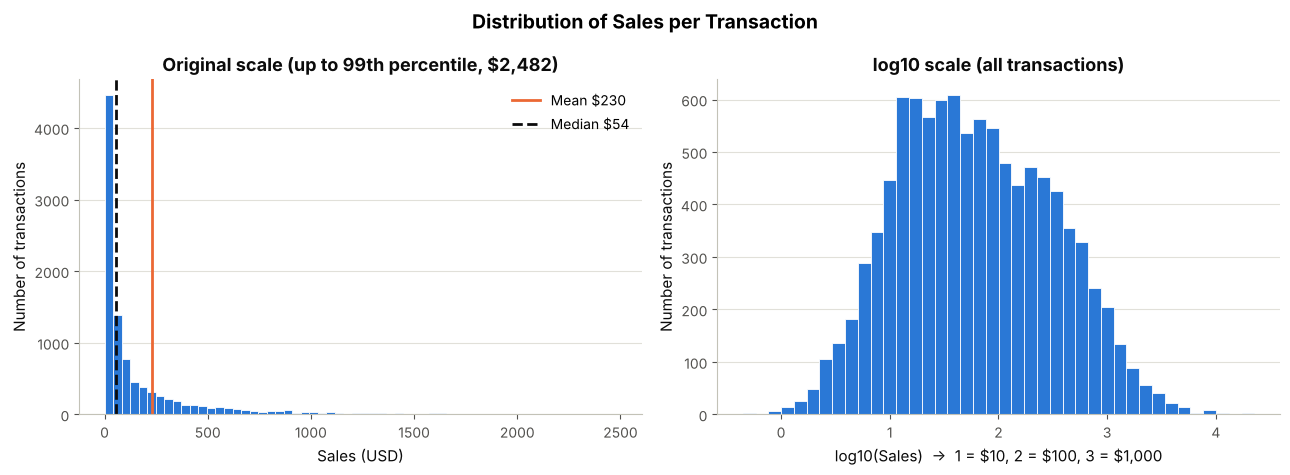

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sales_p99 = df["Sales"].quantile(0.99)
axes[0].hist(df.loc[df["Sales"] <= sales_p99, "Sales"], bins=60, color=BLUE, edgecolor="white", linewidth=0.6)
axes[0].axvline(df["Sales"].mean(), color=ORANGE, linewidth=2, label=f"Mean ${df['Sales'].mean():,.0f}")
axes[0].axvline(df["Sales"].median(), color=INK, linewidth=2, linestyle="--",
                label=f"Median ${df['Sales'].median():,.0f}")
axes[0].set_title(f"Original scale (up to 99th percentile, ${sales_p99:,.0f})")
axes[0].set_xlabel("Sales (USD)")
axes[0].set_ylabel("Number of transactions")
axes[0].legend()

axes[1].hist(np.log10(df.loc[df["Sales"] > 0, "Sales"]), bins=40, color=BLUE, edgecolor="white", linewidth=0.6)
axes[1].set_title("log10 scale (all transactions)")
axes[1].set_xlabel("log10(Sales)  ->  1 = $10, 2 = $100, 3 = $1,000")
axes[1].set_ylabel("Number of transactions")
fig.suptitle("Distribution of Sales per Transaction", fontsize=14, fontweight="bold")
fig.tight_layout()
save_chart(fig, "03_sales_histogram")
plt.show()

### 10.4 Profit distribution — histogram with density curve

Chart saved -> outputs/charts/04_profit_histogram_kde.png


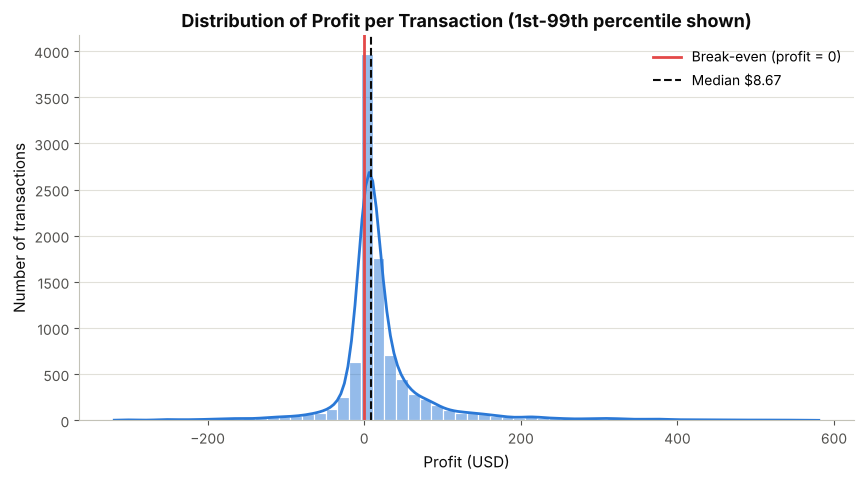

Hidden extremes: 100 rows below $-319 and 100 rows above $581 (still included in all calculations)


In [21]:
low, high = df["Profit"].quantile([0.01, 0.99])
central_profit = df.loc[df["Profit"].between(low, high), "Profit"]

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(central_profit, bins=60, kde=True, color=BLUE, edgecolor="white", ax=ax,
             line_kws={"linewidth": 2})
ax.axvline(0, color=RED, linewidth=2, label="Break-even (profit = 0)")
ax.axvline(df["Profit"].median(), color=INK, linestyle="--", linewidth=1.5,
           label=f"Median ${df['Profit'].median():,.2f}")
ax.set_title("Distribution of Profit per Transaction (1st-99th percentile shown)")
ax.set_xlabel("Profit (USD)")
ax.set_ylabel("Number of transactions")
ax.legend()
save_chart(fig, "04_profit_histogram_kde")
plt.show()
print(f"Hidden extremes: {int((df['Profit'] < low).sum())} rows below ${low:,.0f} "
      f"and {int((df['Profit'] > high).sum())} rows above ${high:,.0f} (still included in all calculations)")

### 10.5 Box plots of Sales and Profit

Chart saved -> outputs/charts/05_sales_boxplot.png


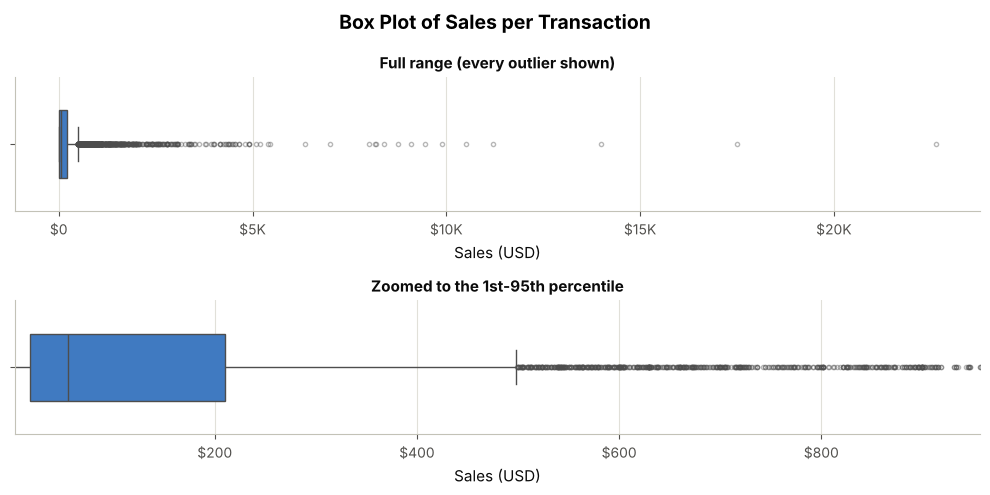

Chart saved -> outputs/charts/06_profit_boxplot.png


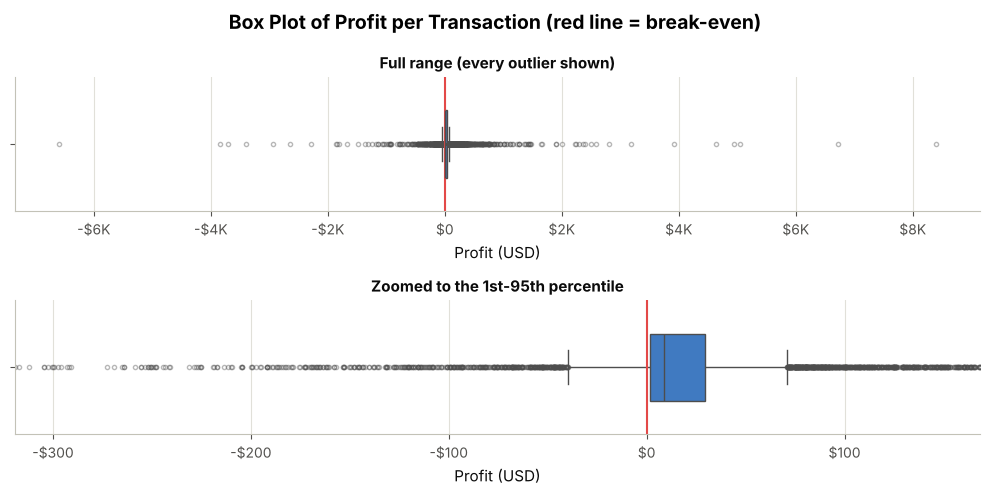

In [22]:
def box_full_and_zoom(column, title, chart_name):
    """Top: full range with every outlier. Bottom: zoom on the box (1st-95th percentile)."""
    fig, axes = plt.subplots(2, 1, figsize=(10, 5))
    for ax, zoom in [(axes[0], False), (axes[1], True)]:
        sns.boxplot(x=df[column], color=BLUE, ax=ax, width=0.5,
                    flierprops={"marker": "o", "markersize": 3, "alpha": 0.4})
        ax.grid(axis="x")
        ax.xaxis.set_major_formatter(MONEY_FMT)
        if column == "Profit":
            ax.axvline(0, color=RED, linewidth=1.5)
        if zoom:
            ax.set_xlim(df[column].quantile(0.01), df[column].quantile(0.95))
            ax.set_title("Zoomed to the 1st-95th percentile", fontsize=11)
        else:
            ax.set_title("Full range (every outlier shown)", fontsize=11)
        ax.set_xlabel(f"{column} (USD)")
    fig.suptitle(title, fontsize=14, fontweight="bold")
    fig.tight_layout()
    save_chart(fig, chart_name)
    plt.show()


box_full_and_zoom("Sales", "Box Plot of Sales per Transaction", "05_sales_boxplot")
box_full_and_zoom("Profit", "Box Plot of Profit per Transaction (red line = break-even)", "06_profit_boxplot")

**How to read a box plot**
- The box spans Q1 to Q3 (middle 50% of transactions); the line inside is the median.
- Whiskers reach the furthest points inside the 1.5×IQR fences; dots beyond them are IQR outliers.

**Result in this run**
- **Sales histogram:** a tall spike of small transactions with a long right tail. On the log scale the shape is roughly bell-shaped, centred near $50 (log ≈ 1.7).
  - Real-world use: analysts log-transform skewed money values before comparing groups or feeding them to models.
- **Profit histogram:** most profits are just above $0 (median $8.67), with a visible left tail of losses.
- **Box plots:** the full-range panels are squeezed by extreme outliers; the zoomed panels show the box itself.
  - Sales: middle 50% is between $17 and $210.
  - Profit: middle 50% is between $1.73 and $29.36.

### 10.6 Quantity and Discount distributions (subplots)

Chart saved -> outputs/charts/07_quantity_discount_distribution.png


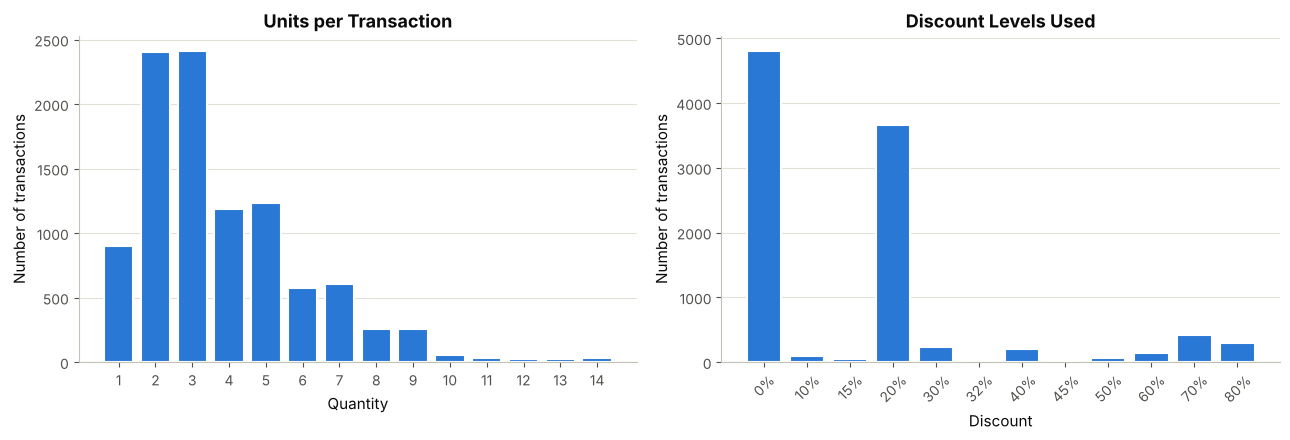

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
qty_counts = df["Quantity"].value_counts().sort_index()
axes[0].bar(qty_counts.index, qty_counts.values, color=BLUE, edgecolor="white", linewidth=1.5)
axes[0].set_title("Units per Transaction")
axes[0].set_xlabel("Quantity")
axes[0].set_ylabel("Number of transactions")
axes[0].set_xticks(qty_counts.index)

disc_counts = df["Discount"].value_counts().sort_index()
axes[1].bar([f"{d:.0%}" for d in disc_counts.index], disc_counts.values, color=BLUE,
            edgecolor="white", linewidth=1.5)
axes[1].set_title("Discount Levels Used")
axes[1].set_xlabel("Discount")
axes[1].set_ylabel("Number of transactions")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()
save_chart(fig, "07_quantity_discount_distribution")
plt.show()

### 10.7 Density plot — profit margin by category

Chart saved -> outputs/charts/08_margin_density_by_category.png


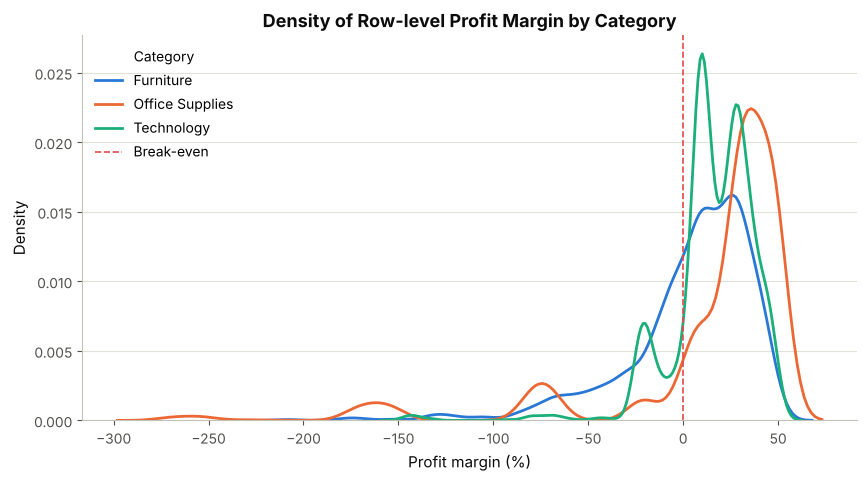

In [24]:
fig, ax = plt.subplots(figsize=(10, 5))
for cat in CATEGORY_ORDER:
    sns.kdeplot(df.loc[df["Category"] == cat, "Profit Margin (%)"], ax=ax, color=CATEGORY_COLORS[cat],
                linewidth=2, label=cat, bw_adjust=0.8)
ax.axvline(0, color=RED, linestyle="--", linewidth=1.2, label="Break-even")
ax.set_title("Density of Row-level Profit Margin by Category")
ax.set_xlabel("Profit margin (%)")
ax.set_ylabel("Density")
ax.legend(title="Category")
save_chart(fig, "08_margin_density_by_category")
plt.show()

### 10.8 Categorical variables — frequency tables, pie chart and bar chart

Frequency table - Category


,rows,percent
Category,,
Office Supplies,6026,60.30
Furniture,2121,21.22
Technology,1847,18.48


Table saved -> outputs/summary_tables/frequency_category.csv
Frequency table - Segment


,rows,percent
Segment,,
Consumer,5191,51.94
Corporate,3020,30.22
Home Office,1783,17.84


Table saved -> outputs/summary_tables/frequency_segment.csv
Frequency table - Region


,rows,percent
Region,,
West,3203,32.05
East,2848,28.50
Central,2323,23.24
South,1620,16.21


Table saved -> outputs/summary_tables/frequency_region.csv
Frequency table - Ship Mode


,rows,percent
Ship Mode,,
Standard Class,5968,59.72
Second Class,1945,19.46
First Class,1538,15.39
Same Day,543,5.43


Table saved -> outputs/summary_tables/frequency_ship_mode.csv


Chart saved -> outputs/charts/09_segment_sales_pie.png


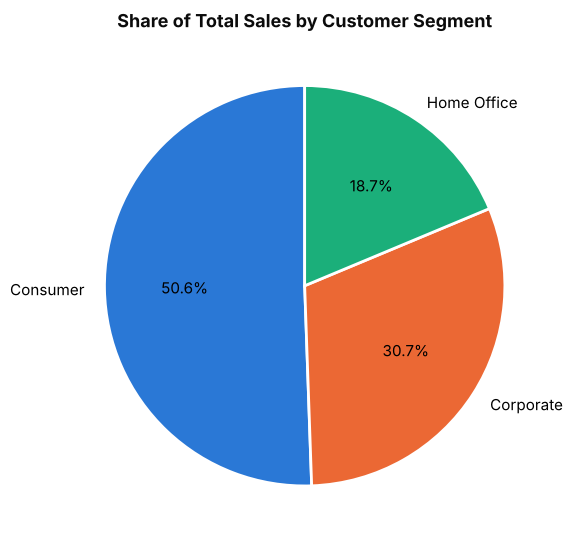

Chart saved -> outputs/charts/10_subcategory_frequency.png


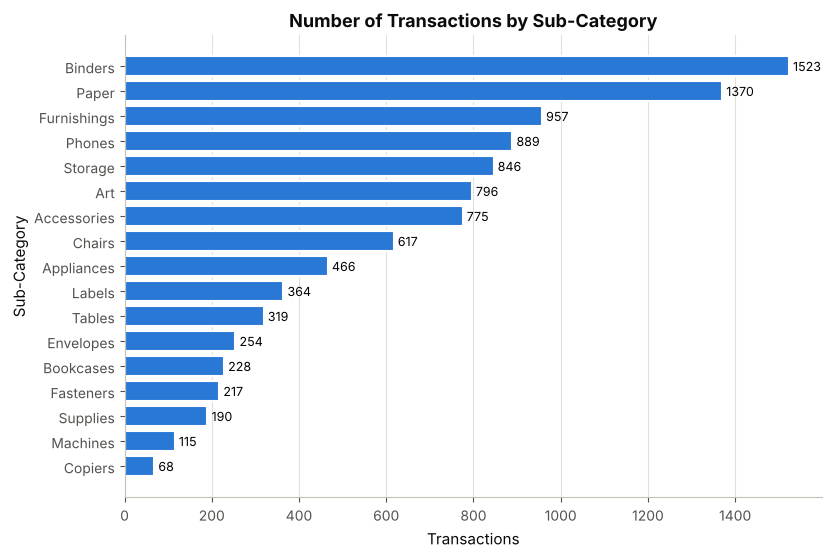

In [25]:
for col in ["Category", "Segment", "Region", "Ship Mode"]:
    if has(col):
        freq = pd.DataFrame({"rows": df[col].value_counts(),
                             "percent": df[col].value_counts(normalize=True) * 100}).round(2)
        print(f"Frequency table - {col}")
        display(freq)
        save_table(freq, f"frequency_{col.lower().replace(' ', '_')}")

if has("Segment"):
    segment_sales = df.groupby("Segment")["Sales"].sum().sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    ax.pie(segment_sales.values, labels=segment_sales.index, autopct="%1.1f%%", startangle=90,
           colors=CATEGORICAL_SLOTS[:len(segment_sales)], wedgeprops={"edgecolor": "white", "linewidth": 2},
           textprops={"fontsize": 11})
    ax.set_title("Share of Total Sales by Customer Segment")
    save_chart(fig, "09_segment_sales_pie")
    plt.show()

if has("Sub-Category"):
    sub_counts = df["Sub-Category"].value_counts().sort_values()
    fig, ax = plt.subplots(figsize=(9, 6))
    ax.barh(sub_counts.index, sub_counts.values, color=BLUE, edgecolor="white", linewidth=1.5)
    ax.bar_label(ax.containers[0], padding=3, fontsize=9)
    ax.set_title("Number of Transactions by Sub-Category")
    ax.set_xlabel("Transactions")
    ax.set_ylabel("Sub-Category")
    ax.grid(False)
    ax.grid(axis="x")
    save_chart(fig, "10_subcategory_frequency")
    plt.show()

**Result in this run**
- **Category:** Office Supplies is **60.3% of transactions** but only 31.3% of sales (many low-price items). Technology is 18.5% of transactions but 36.4% of sales.
- **Segment:** Consumer is 51.9% of transactions and 50.6% of sales (pie chart).
- **Region:** West has the most transactions (32.1%); South has the fewest (16.2%).
- **Ship Mode:** Standard Class is used in 59.7% of transactions.
- **Sub-Category:** Binders (1,523) and Paper (1,370) are the most frequent; Copiers is the least frequent (68) — yet Copiers is the most profitable sub-category (Section 15).
- **Density plot:** Furniture's margin curve sits furthest to the left and has a long negative tail.

## Section 11 — Bivariate Analysis (Unit 4)

- Studies the relationship between **two variables** at a time.
- **Pearson** measures *linear* association; **Spearman** measures *monotonic* association using ranks (robust to outliers and skew).
- **Correlation does not prove causation** — two variables can move together because of a third factor (for example, product type affects both discount and profit).

### 11.1 Pearson and Spearman correlation

In [26]:
pearson = df[VARIABLES].corr(method="pearson").round(3)
spearman = df[VARIABLES].corr(method="spearman").round(3)
print("Pearson correlation:")
display(pearson)
print("Spearman correlation:")
display(spearman)
save_table(pearson, "correlation_pearson")
save_table(spearman, "correlation_spearman")

pairs = [("Sales", "Quantity"), ("Sales", "Profit"), ("Discount", "Profit"), ("Discount", "Sales")]
rows = []
for a, b in pairs:
    row = {"pair": f"{a} vs {b}", "pearson_r": pearson.loc[a, b], "spearman_rho": spearman.loc[a, b]}
    if SCIPY_AVAILABLE:
        row["pearson_p"] = stats.pearsonr(df[a], df[b])[1]
        row["spearman_p"] = stats.spearmanr(df[a], df[b])[1]
    rows.append(row)
key_correlations = pd.DataFrame(rows).set_index("pair")
readable = key_correlations.copy()
for col in [c for c in readable.columns if c.endswith("_p")]:
    readable[col] = readable[col].map(lambda v: "< 1e-300" if v == 0 else f"{v:.1e}")
display(readable)
save_table(key_correlations, "key_correlations")

Pearson correlation:


,Sales,Profit,Quantity,Discount
Sales,1.00,0.48,0.20,-0.03
Profit,0.48,1.00,0.07,-0.22
Quantity,0.20,0.07,1.00,0.01
Discount,-0.03,-0.22,0.01,1.00


Spearman correlation:


,Sales,Profit,Quantity,Discount
Sales,1.00,0.52,0.33,-0.06
Profit,0.52,1.00,0.23,-0.54
Quantity,0.33,0.23,1.00,-0.00
Discount,-0.06,-0.54,-0.00,1.00


Table saved -> outputs/summary_tables/correlation_pearson.csv
Table saved -> outputs/summary_tables/correlation_spearman.csv


,pearson_r,spearman_rho,pearson_p,spearman_p
pair,,,,
Sales vs Quantity,0.20,0.33,2.0e-91,2.2e-248
Sales vs Profit,0.48,0.52,< 1e-300,< 1e-300
Discount vs Profit,-0.22,-0.54,2.7e-109,< 1e-300
Discount vs Sales,-0.03,-0.06,4.8e-03,1.2e-08


Table saved -> outputs/summary_tables/key_correlations.csv


**How to read the output**
- Values range from −1 to +1: near ±1 = strong, near 0 = weak; the sign gives the direction.
- **Rule of thumb:** |r| < 0.1 negligible, 0.1–0.3 weak, 0.3–0.5 moderate, > 0.5 strong.
- A tiny p-value (< 0.05) means the association is unlikely to be zero — it does **not** mean it is large or causal.

**Result in this run**
- **Sales–Profit:** r = 0.48, ρ = 0.52 → moderate positive.
- **Sales–Quantity:** r = 0.20, ρ = 0.33 → weak to moderate positive.
- **Discount–Profit:** r = −0.22 but ρ = **−0.54**.
  - Spearman is much stronger because the relationship is consistent in direction but not a straight line.
  - Profit's extreme outliers also weaken Pearson.
- **Discount–Sales:** ≈ −0.03 → discounts are not associated with larger transactions.
- All p-values are below 0.01 (9,994 rows make even tiny correlations significant). Only Sales–Profit and Discount–Profit (Spearman) are large enough to matter in practice.
- **Correlation is not causation:** for example, products such as tables may get both high discounts and low margins because of their product type.

### 11.2 Sales vs Quantity — scatter plot

Chart saved -> outputs/charts/11_sales_vs_quantity.png


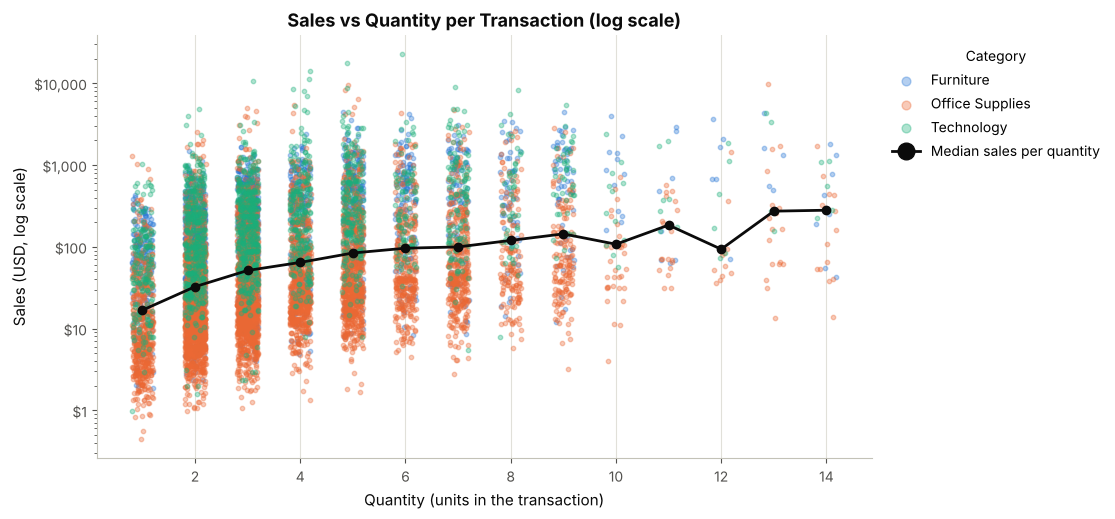

In [27]:
fig, ax = plt.subplots(figsize=(10, 5.5))
jitter = np.random.uniform(-0.2, 0.2, len(df))     # spreads points so they do not overlap
for cat in CATEGORY_ORDER:
    part = df["Category"] == cat
    ax.scatter(df.loc[part, "Quantity"] + jitter[part.values], df.loc[part, "Sales"], s=10, alpha=0.35,
               color=CATEGORY_COLORS[cat], label=cat)
median_sales = df.groupby("Quantity")["Sales"].median()
ax.plot(median_sales.index, median_sales.values, color=INK, linewidth=2, marker="o", markersize=6,
        label="Median sales per quantity")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"${v:,.0f}"))
ax.set_title("Sales vs Quantity per Transaction (log scale)")
ax.set_xlabel("Quantity (units in the transaction)")
ax.set_ylabel("Sales (USD, log scale)")
ax.grid(axis="both")
ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left", markerscale=2)
save_chart(fig, "11_sales_vs_quantity")
plt.show()

### 11.3 Discount vs Profit — scatter plot

Chart saved -> outputs/charts/12_discount_vs_profit.png


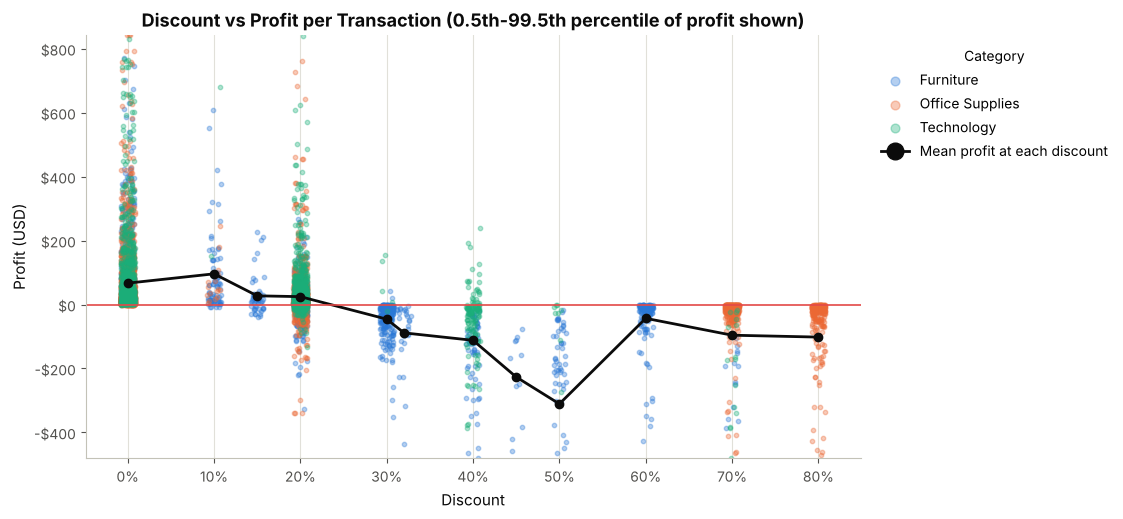

In [28]:
fig, ax = plt.subplots(figsize=(10, 5.5))
jitter = np.random.uniform(-0.008, 0.008, len(df))
for cat in CATEGORY_ORDER:
    part = df["Category"] == cat
    ax.scatter(df.loc[part, "Discount"] + jitter[part.values], df.loc[part, "Profit"], s=10, alpha=0.35,
               color=CATEGORY_COLORS[cat], label=cat)
mean_profit = df.groupby("Discount")["Profit"].mean()
ax.plot(mean_profit.index, mean_profit.values, color=INK, linewidth=2, marker="o", markersize=6,
        label="Mean profit at each discount")
ax.axhline(0, color=RED, linewidth=1.2)
ax.set_ylim(df["Profit"].quantile(0.005), df["Profit"].quantile(0.995))
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_title("Discount vs Profit per Transaction (0.5th-99.5th percentile of profit shown)")
ax.set_xlabel("Discount")
ax.set_ylabel("Profit (USD)")
ax.yaxis.set_major_formatter(MONEY_FMT)
ax.grid(axis="both")
ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left", markerscale=2)
save_chart(fig, "12_discount_vs_profit")
plt.show()

**Result in this run**
- **Sales vs Quantity:** median sales rise from about $17 at 1 unit to about $144 at 9 units.
  - Within each quantity level, sales still range from a few dollars to thousands.
  - So the item's price matters far more than how many units are bought.
- **Discount vs Profit:**
  - Mean profit per row is positive at 0–20% discount (about +$25 to +$96).
  - It is negative at every discount of 30% and above, reaching about **−$311 at 50%**.
  - The points above 40% discount sit almost entirely below the break-even line.

### 11.4 Numerical vs categorical — box plot and violin plot

Chart saved -> outputs/charts/13_profit_boxplot_by_category.png


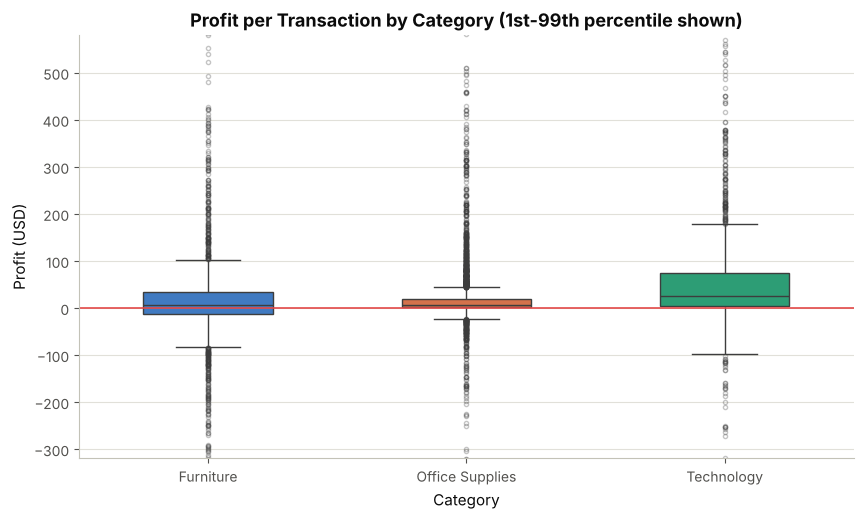

Chart saved -> outputs/charts/14_margin_violin_by_category.png


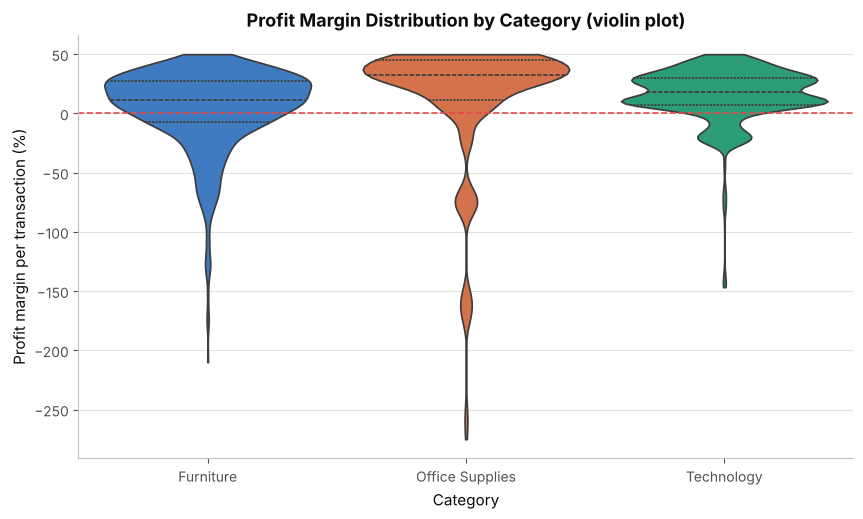

,mean_profit,median_profit,mean_margin_pct,loss_rows_pct
Category,,,,
Furniture,8.70,7.77,3.88,33.66
Office Supplies,20.33,6.88,13.80,14.70
Technology,78.75,25.02,15.61,14.67


Table saved -> outputs/summary_tables/profit_by_category_stats.csv


In [29]:
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(data=df, x="Category", y="Profit", order=CATEGORY_ORDER, hue="Category", palette=CATEGORY_COLORS,
            legend=False, ax=ax, width=0.5, flierprops={"marker": "o", "markersize": 3, "alpha": 0.3})
ax.axhline(0, color=RED, linewidth=1.2)
ax.set_ylim(df["Profit"].quantile(0.01), df["Profit"].quantile(0.99))
ax.set_title("Profit per Transaction by Category (1st-99th percentile shown)")
ax.set_xlabel("Category")
ax.set_ylabel("Profit (USD)")
save_chart(fig, "13_profit_boxplot_by_category")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.violinplot(data=df, x="Category", y="Profit Margin (%)", order=CATEGORY_ORDER, hue="Category",
               palette=CATEGORY_COLORS, legend=False, cut=0, inner="quartile", ax=ax)
ax.axhline(0, color=RED, linewidth=1.2, linestyle="--")
ax.set_title("Profit Margin Distribution by Category (violin plot)")
ax.set_xlabel("Category")
ax.set_ylabel("Profit margin per transaction (%)")
save_chart(fig, "14_margin_violin_by_category")
plt.show()

numeric_by_category = df.groupby("Category").agg(
    mean_profit=("Profit", "mean"), median_profit=("Profit", "median"),
    mean_margin_pct=("Profit Margin (%)", "mean"), loss_rows_pct=("Is Loss", "mean"))
numeric_by_category["loss_rows_pct"] *= 100
display(numeric_by_category.round(2))
save_table(numeric_by_category, "profit_by_category_stats")

### 11.5 Grouped and stacked bar charts

Chart saved -> outputs/charts/15_segment_category_grouped_bar.png


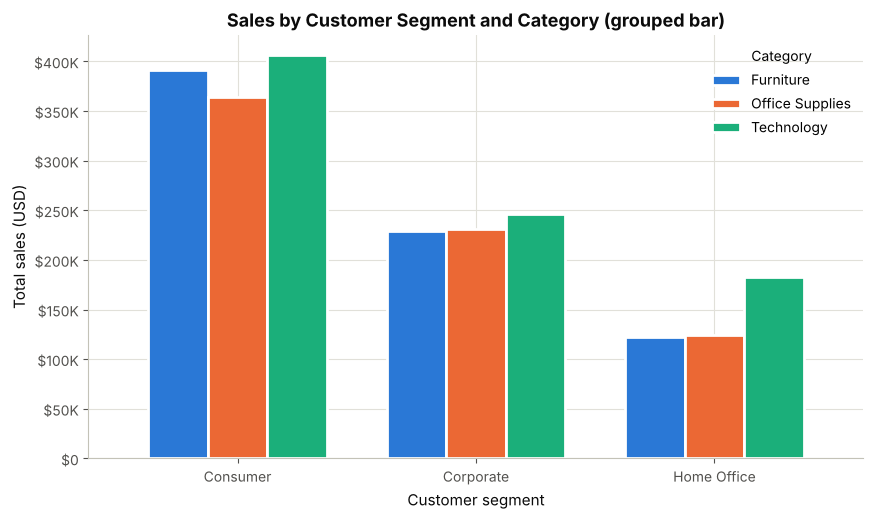

Chart saved -> outputs/charts/16_region_category_stacked_bar.png


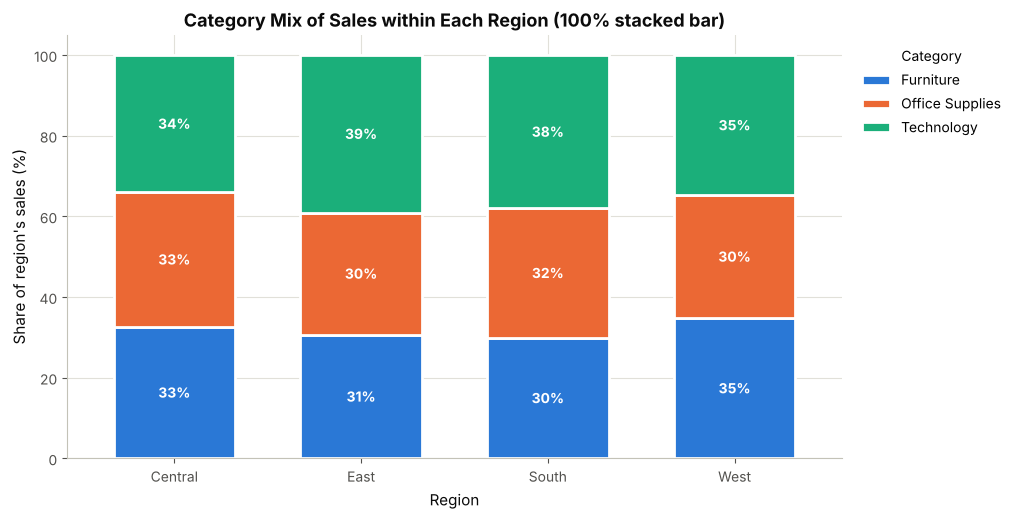

In [30]:
if has("Segment"):
    seg_cat = df.pivot_table(index="Segment", columns="Category", values="Sales", aggfunc="sum")
    fig, ax = plt.subplots(figsize=(10, 5.5))
    seg_cat[CATEGORY_ORDER].plot(kind="bar", ax=ax, color=[CATEGORY_COLORS[c] for c in CATEGORY_ORDER],
                                 width=0.75, edgecolor="white", linewidth=2)
    ax.set_title("Sales by Customer Segment and Category (grouped bar)")
    ax.set_xlabel("Customer segment")
    ax.set_ylabel("Total sales (USD)")
    ax.yaxis.set_major_formatter(MONEY_FMT)
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Category")
    save_chart(fig, "15_segment_category_grouped_bar")
    plt.show()

if has("Region"):
    reg_cat = df.pivot_table(index="Region", columns="Category", values="Sales", aggfunc="sum")
    reg_cat_share = reg_cat.div(reg_cat.sum(axis=1), axis=0) * 100
    fig, ax = plt.subplots(figsize=(10, 5.5))
    reg_cat_share[CATEGORY_ORDER].plot(kind="bar", stacked=True, ax=ax,
                                       color=[CATEGORY_COLORS[c] for c in CATEGORY_ORDER],
                                       width=0.65, edgecolor="white", linewidth=2)
    for container in ax.containers:
        ax.bar_label(container, labels=[f"{v:.0f}%" for v in container.datavalues], label_type="center",
                     color="white", fontsize=10, fontweight="bold")
    ax.set_title("Category Mix of Sales within Each Region (100% stacked bar)")
    ax.set_xlabel("Region")
    ax.set_ylabel("Share of region's sales (%)")
    ax.tick_params(axis="x", rotation=0)
    ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left")
    save_chart(fig, "16_region_category_stacked_bar")
    plt.show()

**Result in this run**
- **Box plot:** Technology has the highest median profit per row ($25.02). Furniture's box extends below $0.
- **Loss-making rows:** 33.7% in Furniture vs 14.7% in both Office Supplies and Technology.
- **Violin plot:** Office Supplies has the highest typical margins but a long tail of deep losses down to about −275%. That tail comes from Binders and Appliances sold at 80% discount.
- **Grouped bar:** the Consumer segment leads in every category; Home Office buys relatively more Technology.
- **Stacked bar:** the category mix is similar in every region (each category 30–39% of a region's sales). So regional profit gaps are unlikely to be explained by product mix alone.

## Section 12 — Multivariate Analysis (Unit 5)

- Studies **three or more variables together** to find patterns a single pair cannot show.
- Tools: correlation heatmap, pair plot, region × category heatmaps, sub-category × region heatmap, optional 3D plot and PCA.

### 12.1 Correlation heatmaps

Chart saved -> outputs/charts/17_correlation_heatmap.png


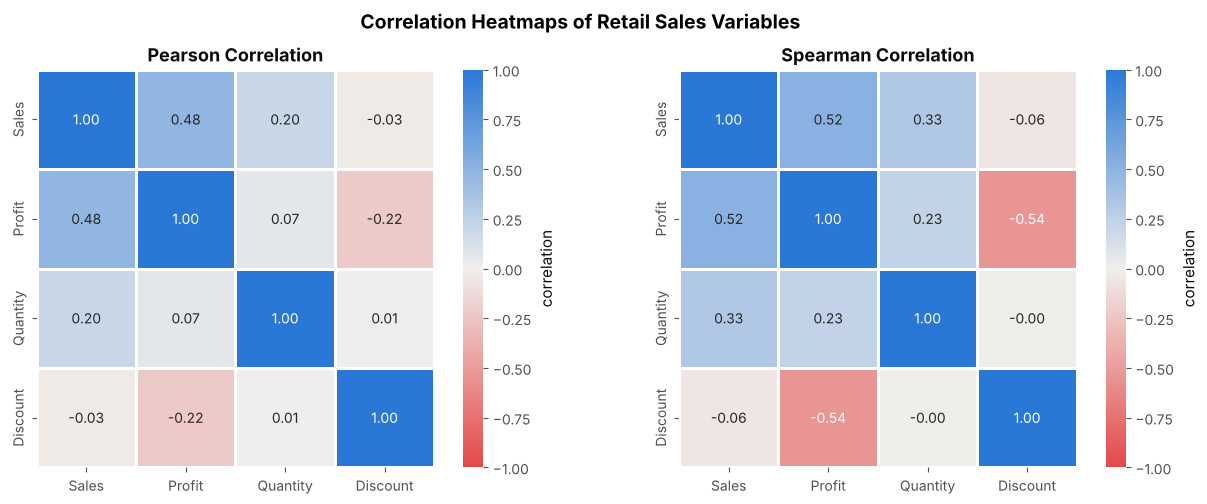

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, matrix, name in [(axes[0], pearson, "Pearson"), (axes[1], spearman, "Spearman")]:
    sns.heatmap(matrix, annot=True, fmt=".2f", cmap=DIVERGING_CMAP, vmin=-1, vmax=1, center=0,
                square=True, linewidths=2, linecolor="white", cbar_kws={"label": "correlation"}, ax=ax)
    ax.set_title(f"{name} Correlation")
fig.suptitle("Correlation Heatmaps of Retail Sales Variables", fontsize=14, fontweight="bold")
fig.tight_layout()
save_chart(fig, "17_correlation_heatmap")
plt.show()

### 12.2 Pair plot (scatterplot matrix)

Chart saved -> outputs/charts/18_pair_plot.png


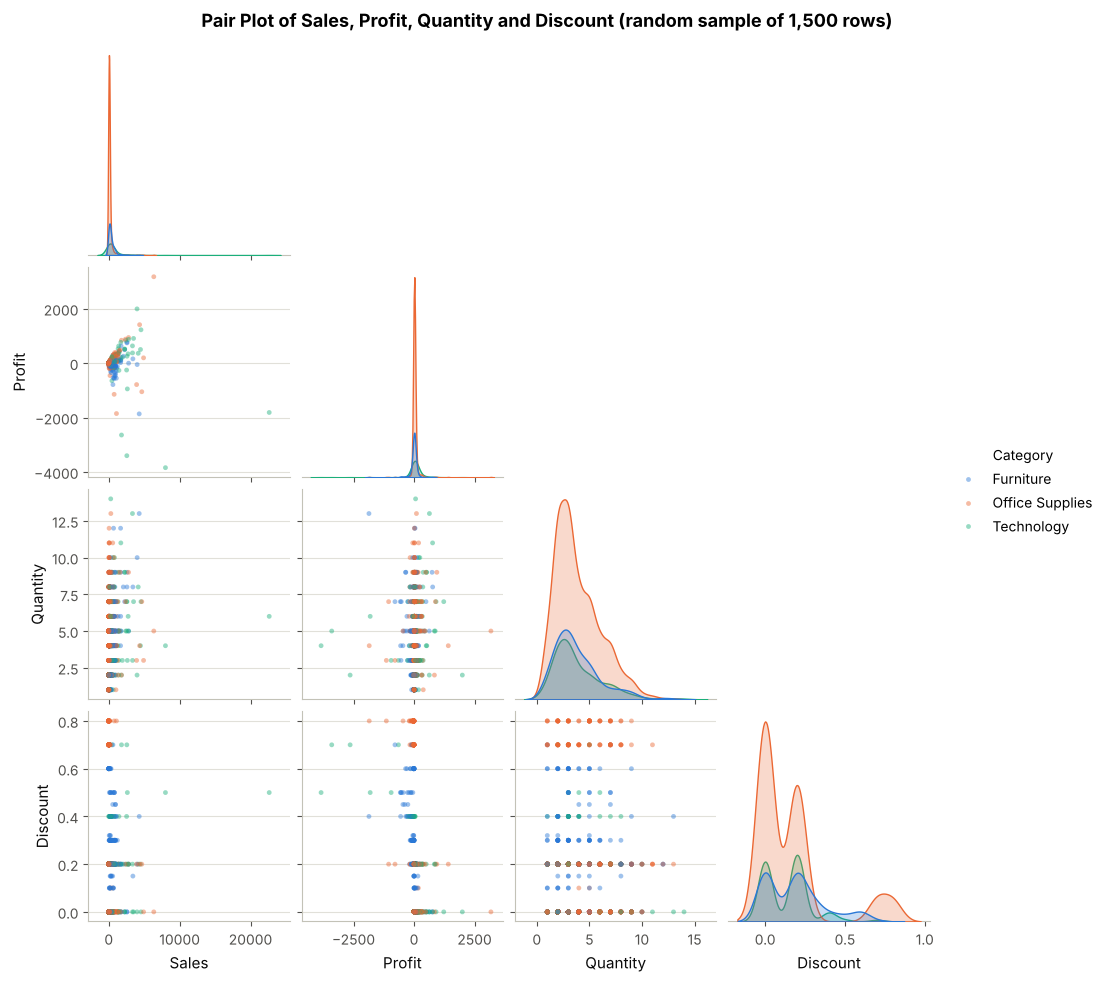

In [32]:
pair_sample = df[VARIABLES + ["Category"]].sample(n=min(1500, len(df)), random_state=RANDOM_STATE)
grid = sns.pairplot(pair_sample, vars=VARIABLES, hue="Category", hue_order=CATEGORY_ORDER,
                    palette=CATEGORY_COLORS, corner=True, diag_kind="kde",
                    plot_kws={"s": 12, "alpha": 0.45, "edgecolor": "none"}, height=2.4)
grid.figure.suptitle("Pair Plot of Sales, Profit, Quantity and Discount (random sample of 1,500 rows)",
                     y=1.02, fontsize=13, fontweight="bold")
save_chart(grid.figure, "18_pair_plot")
plt.show()

**What the code does**
- A pair plot draws a scatter plot for every pair of variables and a density curve for each variable on the diagonal.
- A random sample of 1,500 rows keeps it fast and readable; `random_state` makes the sample reproducible.

### 12.3 Region × Category profit heatmaps

Chart saved -> outputs/charts/19_region_category_heatmap.png


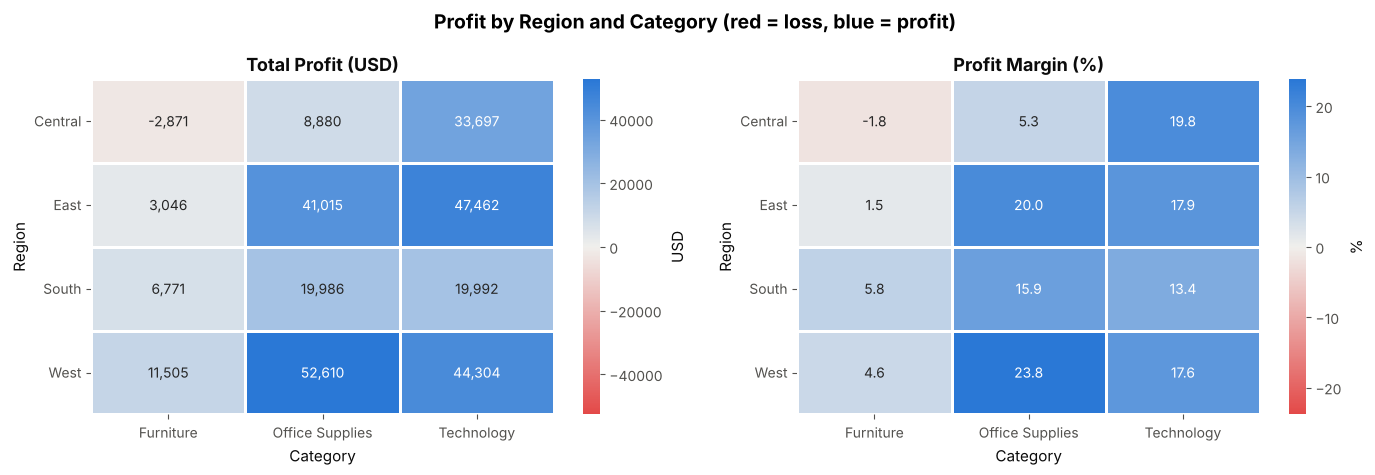

Table saved -> outputs/summary_tables/region_category_profit.csv
Table saved -> outputs/summary_tables/region_category_margin.csv


In [33]:
if has("Region"):
    reg_cat_profit = df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum")
    reg_cat_sales = df.pivot_table(index="Region", columns="Category", values="Sales", aggfunc="sum")
    reg_cat_margin = reg_cat_profit / reg_cat_sales * 100

    fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
    limit = reg_cat_profit.abs().max().max()
    sns.heatmap(reg_cat_profit, annot=True, fmt=",.0f", cmap=DIVERGING_CMAP, center=0, vmin=-limit, vmax=limit,
                linewidths=2, linecolor="white", cbar_kws={"label": "USD"}, ax=axes[0])
    axes[0].set_title("Total Profit (USD)")
    limit = reg_cat_margin.abs().max().max()
    sns.heatmap(reg_cat_margin, annot=True, fmt=".1f", cmap=DIVERGING_CMAP, center=0, vmin=-limit, vmax=limit,
                linewidths=2, linecolor="white", cbar_kws={"label": "%"}, ax=axes[1])
    axes[1].set_title("Profit Margin (%)")
    for ax in axes:
        ax.tick_params(axis="y", rotation=0)
    fig.suptitle("Profit by Region and Category (red = loss, blue = profit)", fontsize=14, fontweight="bold")
    fig.tight_layout()
    save_chart(fig, "19_region_category_heatmap")
    plt.show()
    save_table(reg_cat_profit.round(2), "region_category_profit")
    save_table(reg_cat_margin.round(2), "region_category_margin")

### 12.4 Sub-Category × Region profit heatmap

Chart saved -> outputs/charts/20_subcategory_region_heatmap.png


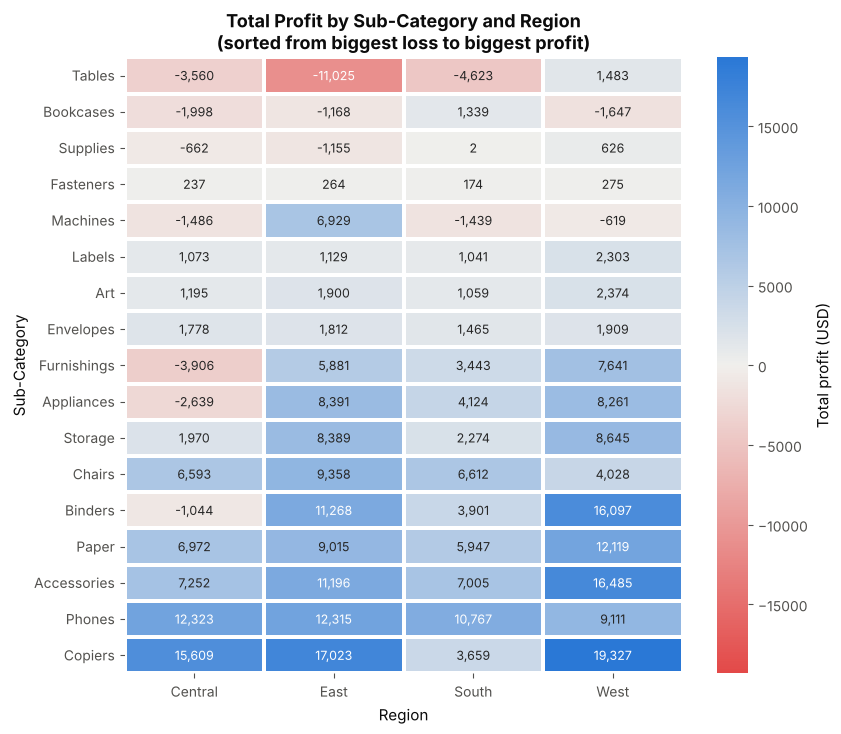

Table saved -> outputs/summary_tables/subcategory_region_profit.csv


In [34]:
if has("Region") and has("Sub-Category"):
    sub_reg = df.pivot_table(index="Sub-Category", columns="Region", values="Profit", aggfunc="sum")
    sub_reg = sub_reg.loc[sub_reg.sum(axis=1).sort_values().index]
    limit = sub_reg.abs().max().max()
    fig, ax = plt.subplots(figsize=(9, 8))
    sns.heatmap(sub_reg, annot=True, fmt=",.0f", cmap=DIVERGING_CMAP, center=0, vmin=-limit, vmax=limit,
                linewidths=1.5, linecolor="white", cbar_kws={"label": "Total profit (USD)"}, ax=ax,
                annot_kws={"fontsize": 9})
    ax.set_title("Total Profit by Sub-Category and Region\n(sorted from biggest loss to biggest profit)")
    ax.set_xlabel("Region")
    ax.set_ylabel("Sub-Category")
    save_chart(fig, "20_subcategory_region_heatmap")
    plt.show()
    save_table(sub_reg.round(2), "subcategory_region_profit")

### 12.5 Three-way summary: Segment × Region × Category

In [35]:
if has("Segment") and has("Region"):
    three_way = df.pivot_table(index=["Segment", "Region"], columns="Category",
                               values=["Sales", "Profit"], aggfunc="sum").round(0)
    display(three_way)
    save_table(three_way, "segment_region_category")

    worst_cells = (df.groupby(["Segment", "Region", "Category"])
                     .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
                     .assign(Margin_pct=lambda t: t["Profit"] / t["Sales"] * 100)
                     .sort_values("Profit").head(5))
    print("Five weakest Segment-Region-Category combinations by total profit:")
    display(worst_cells.round(2))

Profit                                 Sales                           
Category            Furniture Office Supplies Technology  Furniture Office Supplies Technology
Segment     Region                                                                            
Consumer    Central -3,994.00        2,583.00   9,975.00  86,229.00       93,111.00  72,691.00
            East     2,038.00       19,223.00  19,930.00 114,212.00      101,255.00 135,441.00
            South    4,617.00        9,190.00  13,107.00  70,800.00       59,505.00  65,276.00
            West     4,331.00       25,334.00  27,786.00 119,808.00      110,081.00 132,992.00
Corporate   Central  2,322.00           99.00  16,283.00  52,086.00       41,138.00  64,773.00
            East       342.00       13,458.00   9,823.00  64,209.00       66,475.00  69,726.00
            South      952.00        8,143.00   6,121.00  29,645.00       45,930.00  46,311.00
            West     3,969.00       18,528.00  11,941.00  83,080.00       77,134.00  65,641.00
Home Office Central -1,199.00        6,198.00   7,439.00  25,482.00       32,777.00  32,953.00
            East       666.00        8,334.00  17,709.00  29,870.00       37,786.00  59,807.00
            South    1,202.00        2,654.00     765.00  16,853.00       20,217.00  37,185.00
            West     3,206.00        8,748.00   4,577.00  49,725.00       33,638.00  53,359.00

Table saved -> outputs/summary_tables/segment_region_category.csv
Five weakest Segment-Region-Category combinations by total profit:


Sales    Profit  Margin_pct
Segment     Region  Category                                       
Consumer    Central Furniture       86,229.22 -3,994.43       -4.63
Home Office Central Furniture       25,482.34 -1,198.61       -4.70
Corporate   Central Office Supplies 41,137.70     99.29        0.24
            East    Furniture       64,209.05    342.13        0.53
Home Office East    Furniture       29,870.36    665.93        2.23

**Result in this run**
- **Heatmaps:** confirm that only Sales–Profit and Discount–Profit (Spearman −0.54) are notable relationships.
- **Pair plot:**
  - Discount values form horizontal bands.
  - The highest discount bands line up with negative profit in all three categories.
- **Region × Category:**
  - Central–Furniture is the only loss-making cell (−$2,871, −1.8% margin).
  - East–Furniture earns only a 1.5% margin.
  - The best cell is West–Office Supplies (23.8% margin).
- **Sub-Category × Region:**
  - *Tables* lose money in 3 of 4 regions (East −$11,025).
  - *Bookcases* lose in Central, East and West.
  - *Machines* lose in Central, South and West.
  - In Central, *Furnishings*, *Appliances* and *Binders* also lose money, so Central's problem goes beyond one category.
- **Three-way view:** the weakest combinations are Consumer–Central–Furniture (−$3,994, −4.6%) and Home Office–Central–Furniture (−$1,199, −4.7%).

### 12.6 Optional — 3D scatter plot (Unit 2)

- Demonstrates three-dimensional plotting. Wrapped in `try/except` so an error here cannot stop the notebook.

Chart saved -> outputs/charts/21_3d_scatter_optional.png


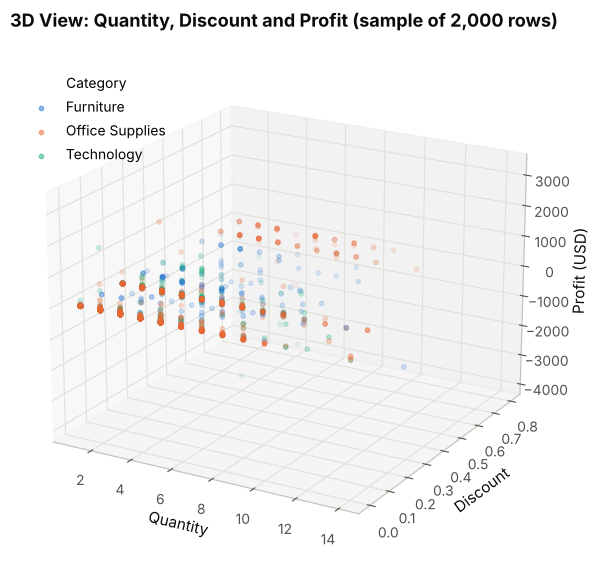

In [36]:
try:
    from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers the 3D projection)
    sample_3d = df[["Quantity", "Discount", "Profit", "Category"]].sample(
        n=min(2000, len(df)), random_state=RANDOM_STATE)
    fig = plt.figure(figsize=(10, 7))
    ax = fig.add_subplot(111, projection="3d")
    for cat in CATEGORY_ORDER:
        part = sample_3d[sample_3d["Category"] == cat]
        ax.scatter(part["Quantity"], part["Discount"], part["Profit"], s=10, alpha=0.5,
                   color=CATEGORY_COLORS[cat], label=cat)
    ax.set_xlabel("Quantity")
    ax.set_ylabel("Discount")
    ax.set_zlabel("Profit (USD)")
    ax.set_title("3D View: Quantity, Discount and Profit (sample of 2,000 rows)")
    ax.view_init(elev=20, azim=-60)
    ax.legend(title="Category", loc="upper left", bbox_to_anchor=(0.0, 0.95))
    save_chart(fig, "21_3d_scatter_optional")
    plt.show()
except Exception as error:
    print("Optional 3D plot skipped:", error)

### 12.7 Optional — PCA for dimensionality reduction (Unit 5)

- PCA turns the 4 correlated numerical variables into new uncorrelated components ordered by how much variation they explain.
- It is **not a prediction model**, so there is no train/test split and no data-leakage risk.
- Variables are standardised first because Sales is measured in dollars and Discount in fractions.

Variance explained by each component:


,explained_variance_pct,cumulative_pct
PC1,39.75,39.75
PC2,26.47,66.22
PC3,22.03,88.25
PC4,11.75,100.00


Loadings (how strongly each variable contributes to each component):


,PC1,PC2,PC3,PC4
Sales,0.64,0.22,-0.31,-0.67
Profit,0.66,-0.20,-0.25,0.68
Quantity,0.29,0.63,0.70,0.16
Discount,-0.27,0.72,-0.59,0.24


Table saved -> outputs/summary_tables/pca_explained_variance.csv
Table saved -> outputs/summary_tables/pca_loadings.csv
Chart saved -> outputs/charts/22_pca_optional.png


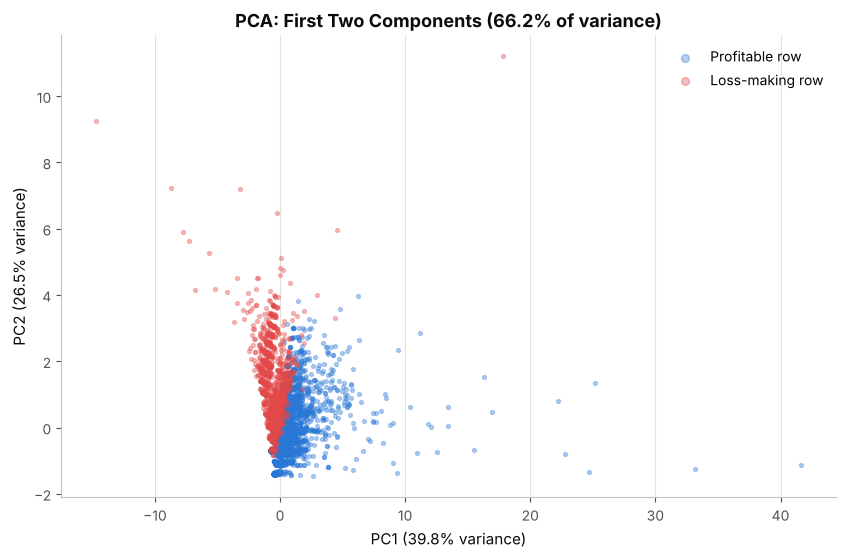

In [37]:
try:
    from sklearn.decomposition import PCA
    from sklearn.preprocessing import StandardScaler

    X = df[VARIABLES].replace([np.inf, -np.inf], np.nan).dropna()
    X_scaled = StandardScaler().fit_transform(X)
    pca = PCA(n_components=4, random_state=RANDOM_STATE).fit(X_scaled)

    variance = pd.DataFrame({
        "explained_variance_pct": pca.explained_variance_ratio_ * 100,
        "cumulative_pct": np.cumsum(pca.explained_variance_ratio_) * 100,
    }, index=[f"PC{i + 1}" for i in range(4)]).round(2)
    loadings = pd.DataFrame(pca.components_.T, index=VARIABLES,
                            columns=[f"PC{i + 1}" for i in range(4)]).round(3)
    print("Variance explained by each component:")
    display(variance)
    print("Loadings (how strongly each variable contributes to each component):")
    display(loadings)
    save_table(variance, "pca_explained_variance")
    save_table(loadings, "pca_loadings")

    scores = pca.transform(X_scaled)[:, :2]
    is_loss = df.loc[X.index, "Is Loss"].to_numpy()
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.scatter(scores[~is_loss, 0], scores[~is_loss, 1], s=8, alpha=0.35, color=BLUE, label="Profitable row")
    ax.scatter(scores[is_loss, 0], scores[is_loss, 1], s=8, alpha=0.35, color=RED, label="Loss-making row")
    ax.set_title(f"PCA: First Two Components ({variance['cumulative_pct'].iloc[1]:.1f}% of variance)")
    ax.set_xlabel(f"PC1 ({variance['explained_variance_pct'].iloc[0]:.1f}% variance)")
    ax.set_ylabel(f"PC2 ({variance['explained_variance_pct'].iloc[1]:.1f}% variance)")
    ax.grid(axis="both")
    ax.legend(markerscale=2)
    save_chart(fig, "22_pca_optional")
    plt.show()
except Exception as error:
    print("Optional PCA skipped:", error)

**Result in this run**
- **PC1 (39.8%)** loads mainly on Sales and Profit → the "size and value of the transaction".
- **PC2 (26.5%)** loads mainly on Discount and Quantity.
- Together they keep **66.2%** of the variation in 2 dimensions instead of 4.
- Loss-making rows gather on the high-PC2, low-PC1 side, i.e. discount-heavy, low-value transactions.
- With only 4 variables, PCA here is a demonstration of the Unit 5 technique, not a requirement.

**Real-world use**
- PCA compresses many correlated features (for example, hundreds of customer metrics) before visualisation or clustering.

## Section 13 — Monthly and Yearly Sales Trends (Unit 2 line plots, annotations, error bars)

Table saved -> outputs/summary_tables/monthly_sales_profit.csv


Chart saved -> outputs/charts/23_monthly_sales_trend.png


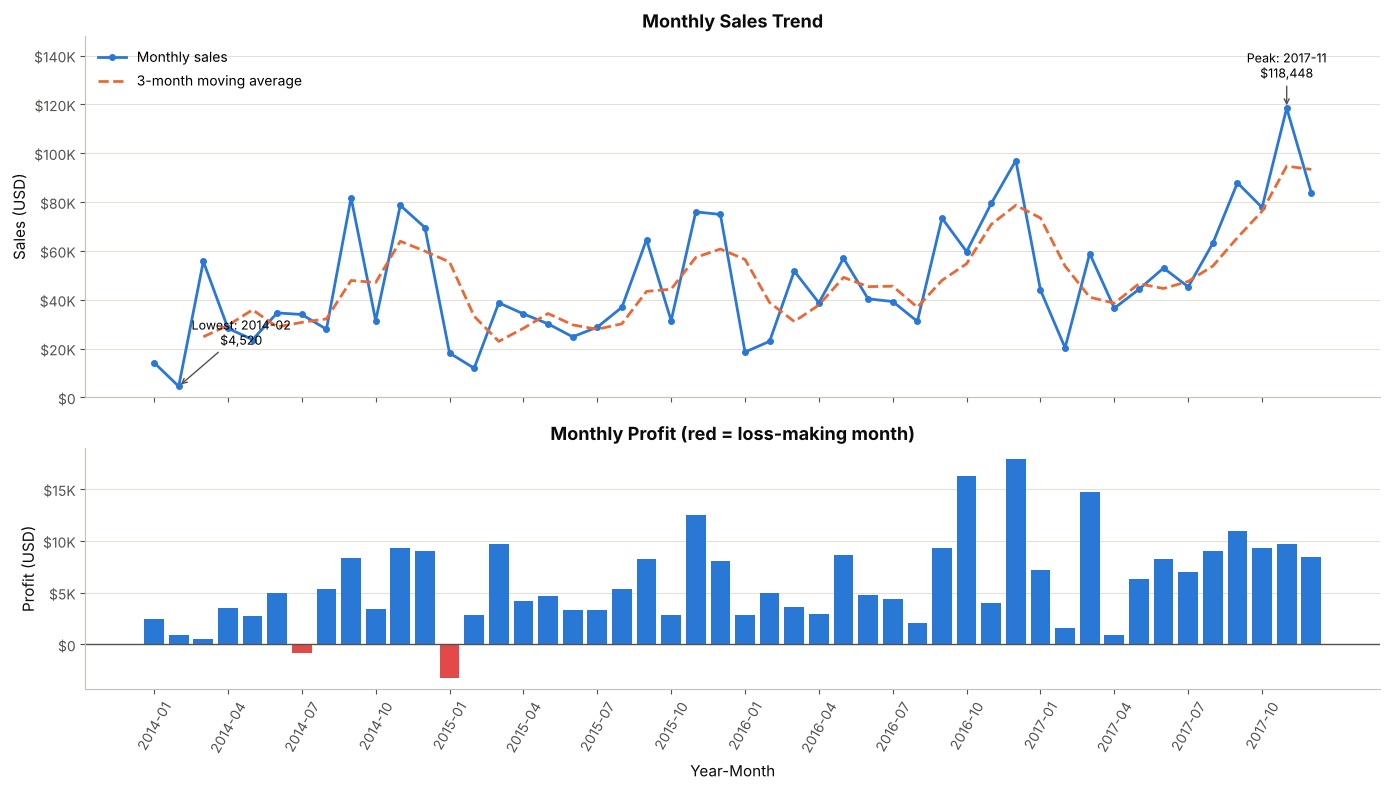

Loss-making months: ['2014-07', '2015-01']


In [38]:
monthly = (df.groupby("Year-Month")
             .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
             .sort_index())
monthly["Sales_3M_avg"] = monthly["Sales"].rolling(3).mean()
save_table(monthly.round(2), "monthly_sales_profit")

x = np.arange(len(monthly))
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, gridspec_kw={"height_ratios": [3, 2]})
axes[0].plot(x, monthly["Sales"], color=BLUE, linewidth=2, marker="o", markersize=4, label="Monthly sales")
axes[0].plot(x, monthly["Sales_3M_avg"], color=ORANGE, linewidth=2, linestyle="--", label="3-month moving average")
peak, low_month = monthly["Sales"].idxmax(), monthly["Sales"].idxmin()
for label, month, offset in [("Peak", peak, (0, 22)), ("Lowest", low_month, (45, 30))]:
    pos = monthly.index.get_loc(month)
    axes[0].annotate(f"{label}: {month}\n${monthly.loc[month, 'Sales']:,.0f}",
                     xy=(pos, monthly.loc[month, "Sales"]), xytext=offset, textcoords="offset points",
                     ha="center", fontsize=9, arrowprops={"arrowstyle": "->", "color": INK_2})
axes[0].set_title("Monthly Sales Trend")
axes[0].set_ylabel("Sales (USD)")
axes[0].yaxis.set_major_formatter(MONEY_FMT)
axes[0].set_ylim(0, monthly["Sales"].max() * 1.25)
axes[0].legend(loc="upper left")

bar_colors = [BLUE if v >= 0 else RED for v in monthly["Profit"]]
axes[1].bar(x, monthly["Profit"], color=bar_colors, width=0.8)
axes[1].axhline(0, color=INK_2, linewidth=1)
axes[1].set_title("Monthly Profit (red = loss-making month)")
axes[1].set_ylabel("Profit (USD)")
axes[1].yaxis.set_major_formatter(MONEY_FMT)
axes[1].set_xticks(x[::3])
axes[1].set_xticklabels(monthly.index[::3], rotation=60)
axes[1].set_xlabel("Year-Month")
fig.tight_layout()
save_chart(fig, "23_monthly_sales_trend")
plt.show()

print("Loss-making months:", monthly.index[monthly["Profit"] < 0].tolist() or "none")

,Sales,Profit,Orders,Margin_pct,Sales_growth_pct
Year,,,,,
2014,"484,247.50","49,543.97",969,10.23,NaN
2015,"470,532.51","61,618.60",1038,13.10,-2.83
2016,"609,205.60","81,795.17",1315,13.43,29.47
2017,"733,215.26","93,439.27",1687,12.74,20.36


Table saved -> outputs/summary_tables/yearly_summary.csv


Chart saved -> outputs/charts/24_yearly_and_seasonal_sales.png


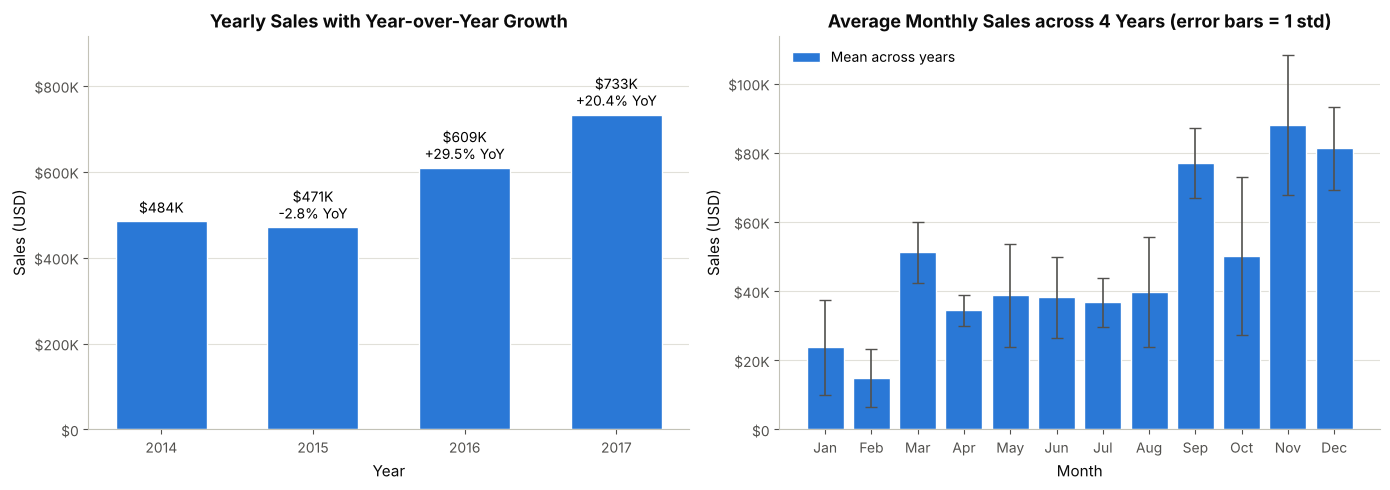

In [39]:
yearly = df.groupby("Year").agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"))
if has("Order ID"):
    yearly["Orders"] = df.groupby("Year")["Order ID"].nunique()
yearly["Margin_pct"] = yearly["Profit"] / yearly["Sales"] * 100
yearly["Sales_growth_pct"] = yearly["Sales"].pct_change() * 100
display(yearly.round(2))
save_table(yearly.round(2), "yearly_summary")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars = axes[0].bar(yearly.index.astype(str), yearly["Sales"], color=BLUE, width=0.6, edgecolor="white")
axes[0].bar_label(bars, labels=[f"${s / 1000:,.0f}K" + ("" if pd.isna(g) else f"\n{g:+.1f}% YoY")
                                for s, g in zip(yearly["Sales"], yearly["Sales_growth_pct"])], padding=4)
axes[0].set_title("Yearly Sales with Year-over-Year Growth")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Sales (USD)")
axes[0].yaxis.set_major_formatter(MONEY_FMT)
axes[0].set_ylim(0, yearly["Sales"].max() * 1.25)

# Error visualization: average sales for each calendar month across years, +/- 1 standard deviation
month_year = df.groupby(["Year", "Month"])["Sales"].sum().unstack("Year")
month_mean, month_std = month_year.mean(axis=1), month_year.std(axis=1)
month_labels = pd.to_datetime(month_mean.index.astype(str), format="%m").strftime("%b")
axes[1].bar(month_labels, month_mean, yerr=month_std, color=BLUE, capsize=4, edgecolor="white",
            error_kw={"ecolor": INK_2, "linewidth": 1.2}, label="Mean across years")
axes[1].set_title(f"Average Monthly Sales across {month_year.shape[1]} Years (error bars = 1 std)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Sales (USD)")
axes[1].yaxis.set_major_formatter(MONEY_FMT)
axes[1].legend(loc="upper left")
fig.tight_layout()
save_chart(fig, "24_yearly_and_seasonal_sales")
plt.show()

**What the code does**
- `rolling(3).mean()` smooths monthly noise to show the underlying direction.
- `annotate()` labels the highest and lowest months with arrows.
- Error bars show how much each calendar month varies from year to year — a short bar means a reliable seasonal pattern.
- Two separate panels are used for sales and profit instead of one chart with two y-axes (dual axes mislead readers).

**Result in this run**
- **Yearly sales:**
  - $484,248 in 2014 and $470,533 in 2015 (−2.8%)
  - then +29.5% in 2016 and +20.4% in 2017, reaching **$733,215**
- **Orders** grew from 969 to 1,687 a year.
- **Margin** improved from 10.2% (2014) to about 13% in 2015–2017.
- **Seasonality:** September, November and December are the strongest months on average; January and February are the weakest.
  - Peak month: **Nov 2017 ($118,448)**. Lowest: **Feb 2014 ($4,520)**.
- **Error bars:** January and February vary most relative to their size, so early-year demand is the least predictable.
- Only two months were loss-making overall: **Jul 2014** and **Jan 2015**.

**Real-world use**
- Retail planners use exactly this seasonal profile to schedule purchasing and staffing before Q4.

## Section 14 — Highest-Sales Products

,Product Name,Category,Total_Sales,Total_Profit,Units,Transactions,Avg_Discount,Margin_pct
404,Canon imageCLASS 2200 Advanced Copier,Technology,"61,599.82","25,199.93",20,5,0.12,40.91
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,"27,453.38","7,753.04",31,10,0.24,28.24
444,Cisco TelePresence System EX90 Videoconferenci...,Technology,"22,638.48","-1,811.08",6,1,0.50,-8.00
786,HON 5400 Series Task Chairs for Big and Tall,Furniture,"21,870.58",0.00,39,8,0.20,0.00
686,GBC DocuBind TL300 Electric Binding System,Office Supplies,"19,823.48","2,233.51",37,11,0.30,11.27
688,GBC Ibimaster 500 Manual ProClick Binding System,Office Supplies,"19,024.50",760.98,48,9,0.52,4.00
805,Hewlett Packard LaserJet 3310 Copier,Technology,"18,839.69","6,983.88",38,8,0.20,37.07
787,HP Designjet T520 Inkjet Large Format Printer ...,Technology,"18,374.90","4,094.98",12,3,0.17,22.29
683,GBC DocuBind P400 Electric Binding System,Office Supplies,"17,965.07","-1,878.17",27,6,0.45,-10.45
813,High Speed Automatic Electric Letter Opener,Office Supplies,"17,030.31",-262.00,11,3,0.07,-1.54


Table saved -> outputs/summary_tables/top10_products_by_sales.csv


Chart saved -> outputs/charts/25_top10_products_sales.png


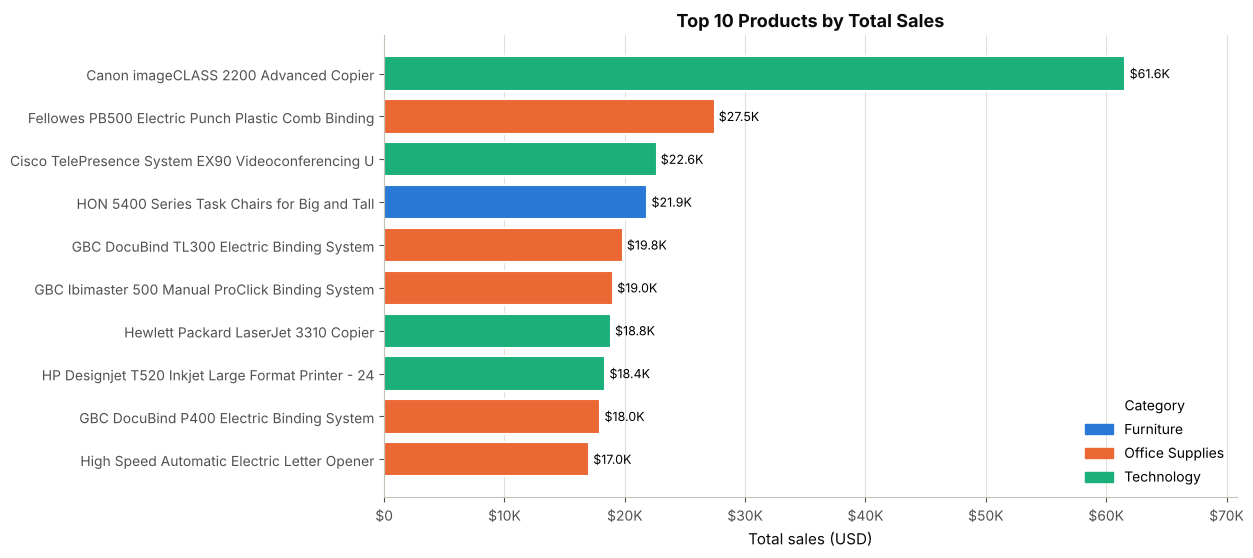

In [40]:
if has("Product Name"):
    product_summary = (df.groupby(["Product Name", "Category"])
                         .agg(Total_Sales=("Sales", "sum"), Total_Profit=("Profit", "sum"),
                              Units=("Quantity", "sum"), Transactions=("Sales", "size"),
                              Avg_Discount=("Discount", "mean"))
                         .reset_index())
    product_summary["Margin_pct"] = product_summary["Total_Profit"] / product_summary["Total_Sales"] * 100

    top_sales = product_summary.nlargest(10, "Total_Sales")
    display(top_sales.round(2))
    save_table(top_sales.round(2), "top10_products_by_sales", index=False)

    plot_data = top_sales.sort_values("Total_Sales")
    fig, ax = plt.subplots(figsize=(11, 6))
    bars = ax.barh(plot_data["Product Name"].str.slice(0, 50), plot_data["Total_Sales"],
                   color=[CATEGORY_COLORS[c] for c in plot_data["Category"]], edgecolor="white", linewidth=1.5)
    ax.bar_label(bars, labels=[f"${v / 1000:,.1f}K" for v in plot_data["Total_Sales"]], padding=3, fontsize=9)
    ax.set_title("Top 10 Products by Total Sales")
    ax.set_xlabel("Total sales (USD)")
    ax.xaxis.set_major_formatter(MONEY_FMT)
    handles = [plt.Rectangle((0, 0), 1, 1, color=CATEGORY_COLORS[c]) for c in CATEGORY_ORDER]
    ax.legend(handles, CATEGORY_ORDER, title="Category", loc="lower right")
    ax.set_xlim(0, plot_data["Total_Sales"].max() * 1.15)
    ax.grid(False)
    ax.grid(axis="x")
    save_chart(fig, "25_top10_products_sales")
    plt.show()
else:
    print("Product Name column not available - product-level analysis skipped.")

**Result in this run**
- **Canon imageCLASS 2200 Advanced Copier** leads with **$61,600** in sales from just 5 transactions, earning $25,200 profit (40.9% margin).
- The top 10 contains 5 Office Supplies, 4 Technology and 1 Furniture product.
- **3 of the top-10 sellers lose money:**
  - Cisco TelePresence EX90 (−$1,811, 50% discount)
  - GBC DocuBind P400 (−$1,878, 45% average discount)
  - High Speed Automatic Electric Letter Opener (−$262)
- HON 5400 task chairs exactly break even ($0 profit).
- So the best sellers are not automatically the best earners.

## Section 15 — Highest-Profit and Loss-Making Products

Top 10 products by total profit:


,Product Name,Category,Total_Sales,Total_Profit,Units,Transactions,Avg_Discount,Margin_pct
404,Canon imageCLASS 2200 Advanced Copier,Technology,"61,599.82","25,199.93",20,5,0.12,40.91
650,Fellowes PB500 Electric Punch Plastic Comb Bin...,Office Supplies,"27,453.38","7,753.04",31,10,0.24,28.24
805,Hewlett Packard LaserJet 3310 Copier,Technology,"18,839.69","6,983.88",38,8,0.20,37.07
400,Canon PC1060 Personal Laser Copier,Technology,"11,619.83","4,570.93",19,4,0.15,39.34
787,HP Designjet T520 Inkjet Large Format Printer ...,Technology,"18,374.90","4,094.98",12,3,0.17,22.29
165,Ativa V4110MDD Micro-Cut Shredder,Technology,"7,699.89","3,772.95",11,2,0.00,49.00
19,"3D Systems Cube Printer, 2nd Generation, Magenta",Technology,"14,299.89","3,717.97",11,2,0.00,26.00
1276,Plantronics Savi W720 Multi-Device Wireless He...,Technology,"9,367.29","3,696.28",24,7,0.06,39.46
895,Ibico EPK-21 Electric Binding System,Office Supplies,"15,875.92","3,345.28",13,3,0.33,21.07
1840,Zebra ZM400 Thermal Label Printer,Technology,"6,965.70","3,343.54",6,2,0.00,48.00


10 products with the largest total losses:


,Product Name,Category,Total_Sales,Total_Profit,Units,Transactions,Avg_Discount,Margin_pct
475,Cubify CubeX 3D Printer Double Head Print,Technology,"11,099.96","-8,879.97",9,3,0.53,-80.00
985,Lexmark MX611dhe Monochrome Laser Printer,Technology,"16,829.90","-4,589.97",18,4,0.40,-27.27
476,Cubify CubeX 3D Printer Triple Head Print,Technology,"7,999.98","-3,839.99",4,1,0.50,-48.00
425,Chromcraft Bull-Nose Wood Oval Conference Tabl...,Furniture,"9,917.64","-2,876.12",27,5,0.28,-29.00
376,Bush Advantage Collection Racetrack Conference...,Furniture,"9,544.72","-1,934.40",33,7,0.35,-20.27
683,GBC DocuBind P400 Electric Binding System,Office Supplies,"17,965.07","-1,878.17",27,6,0.45,-10.45
444,Cisco TelePresence System EX90 Videoconferenci...,Technology,"22,638.48","-1,811.08",6,1,0.50,-8.00
1043,Martin Yale Chadless Opener Electric Letter Op...,Office Supplies,"16,656.20","-1,299.18",22,6,0.10,-7.80
285,Balt Solid Wood Round Tables,Furniture,"6,518.75","-1,201.06",19,4,0.20,-18.42
364,BoxOffice By Design Rectangular and Half-Moon ...,Furniture,"1,706.25","-1,148.44",15,3,0.48,-67.31


Products with negative total profit: 301 of 1,850 (16.3%); combined loss -$77,068.38
Loss-making products by category:


,loss-making products
Category,
Furniture,123
Office Supplies,122
Technology,56


Table saved -> outputs/summary_tables/top10_products_by_profit.csv
Table saved -> outputs/summary_tables/loss_making_products.csv


Chart saved -> outputs/charts/26_bottom10_products_profit.png


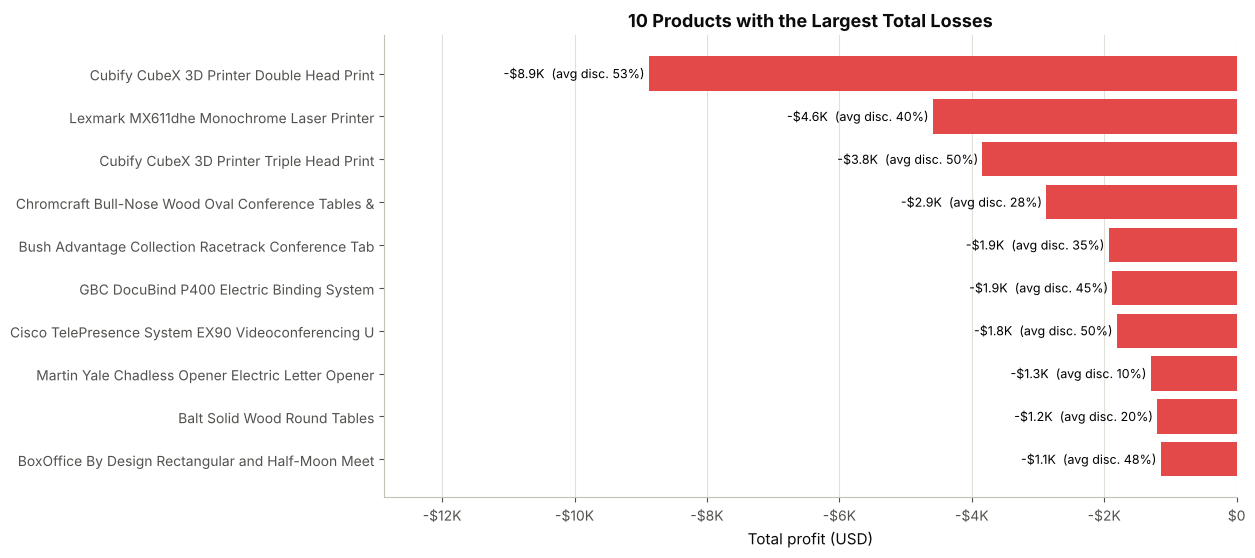

In [41]:
if has("Product Name"):
    top_profit = product_summary.nlargest(10, "Total_Profit")
    bottom_profit = product_summary.nsmallest(10, "Total_Profit")
    loss_products = product_summary[product_summary["Total_Profit"] < 0].sort_values("Total_Profit")

    print("Top 10 products by total profit:")
    display(top_profit.round(2))
    print("10 products with the largest total losses:")
    display(bottom_profit.round(2))
    print(f"Products with negative total profit: {len(loss_products):,} of {len(product_summary):,} "
          f"({len(loss_products) / len(product_summary):.1%}); combined loss -${abs(loss_products['Total_Profit'].sum()):,.2f}")
    print("Loss-making products by category:")
    display(loss_products["Category"].value_counts().to_frame("loss-making products"))

    save_table(top_profit.round(2), "top10_products_by_profit", index=False)
    save_table(loss_products.round(2), "loss_making_products", index=False)

    plot_data = bottom_profit.sort_values("Total_Profit", ascending=False)
    fig, ax = plt.subplots(figsize=(11, 6))
    bars = ax.barh(plot_data["Product Name"].str.slice(0, 50), plot_data["Total_Profit"], color=RED)
    ax.bar_label(bars, labels=[f"-${abs(v) / 1000:,.1f}K  (avg disc. {d:.0%})"
                               for v, d in zip(plot_data["Total_Profit"], plot_data["Avg_Discount"])],
                 padding=3, fontsize=9)
    ax.set_title("10 Products with the Largest Total Losses")
    ax.set_xlabel("Total profit (USD)")
    ax.xaxis.set_major_formatter(MONEY_FMT)
    ax.set_xlim(plot_data["Total_Profit"].min() * 1.45, 0)
    ax.grid(False)
    ax.grid(axis="x")
    save_chart(fig, "26_bottom10_products_profit")
    plt.show()

,Sub-Category,Category,Sales,Profit,Avg_Discount,Margin_pct
16,Tables,Furniture,"206,965.53","-17,725.48",0.26,-8.56
4,Bookcases,Furniture,"114,880.00","-3,472.56",0.21,-3.02
15,Supplies,Office Supplies,"46,673.54","-1,189.10",0.08,-2.55
8,Fasteners,Office Supplies,"3,024.28",949.52,0.08,31.40
11,Machines,Technology,"189,238.63","3,384.76",0.31,1.79
10,Labels,Office Supplies,"12,486.31","5,546.25",0.07,44.42
2,Art,Office Supplies,"27,118.79","6,527.79",0.07,24.07
7,Envelopes,Office Supplies,"16,476.40","6,964.18",0.08,42.27
9,Furnishings,Furniture,"91,705.16","13,059.14",0.14,14.24
1,Appliances,Office Supplies,"107,532.16","18,138.01",0.17,16.87


Table saved -> outputs/summary_tables/subcategory_summary.csv


Chart saved -> outputs/charts/27_subcategory_profit.png


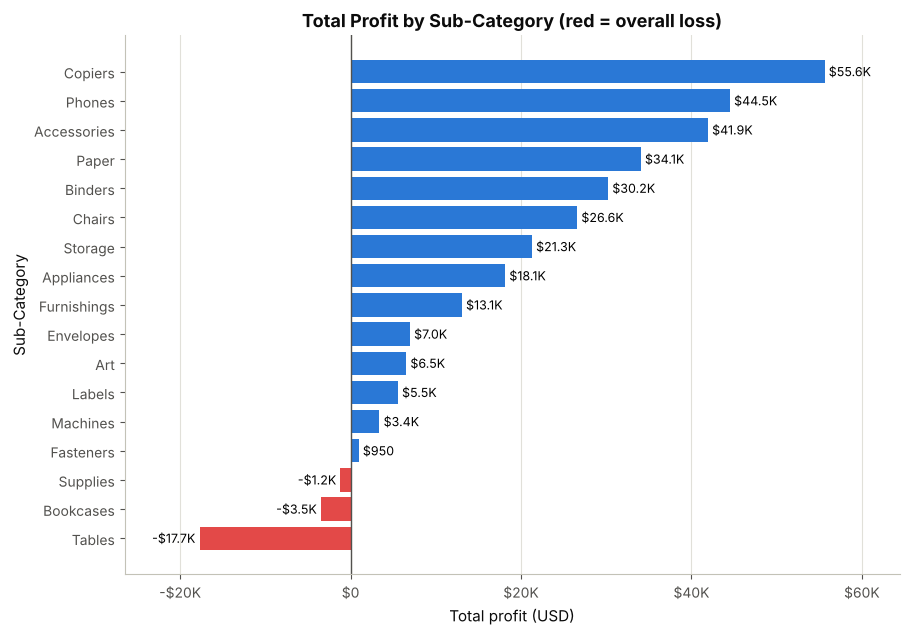

In [42]:
if has("Sub-Category"):
    sub_summary = (df.groupby(["Sub-Category", "Category"])
                     .agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"), Avg_Discount=("Discount", "mean"))
                     .reset_index())
    sub_summary["Margin_pct"] = sub_summary["Profit"] / sub_summary["Sales"] * 100
    sub_summary = sub_summary.sort_values("Profit")
    display(sub_summary.round(2))
    save_table(sub_summary.round(2), "subcategory_summary", index=False)

    fig, ax = plt.subplots(figsize=(10, 7))
    colors = [BLUE if p >= 0 else RED for p in sub_summary["Profit"]]
    bars = ax.barh(sub_summary["Sub-Category"], sub_summary["Profit"], color=colors)
    ax.bar_label(bars, labels=[money_short(v, 1) for v in sub_summary["Profit"]], padding=3, fontsize=9)
    ax.axvline(0, color=INK_2, linewidth=1)
    ax.set_title("Total Profit by Sub-Category (red = overall loss)")
    ax.set_xlabel("Total profit (USD)")
    ax.set_ylabel("Sub-Category")
    ax.xaxis.set_major_formatter(MONEY_FMT)
    span = sub_summary["Profit"].max() - sub_summary["Profit"].min()
    ax.set_xlim(sub_summary["Profit"].min() - span * 0.12, sub_summary["Profit"].max() + span * 0.12)
    ax.grid(False)
    ax.grid(axis="x")
    save_chart(fig, "27_subcategory_profit")
    plt.show()

**Result in this run**
- **301 of 1,850 products (16.3%)** lose money overall, with a combined loss of **$77,068**.
- **Biggest loser:** Cubify CubeX 3D Printer Double Head (**−$8,880**, average discount 53%).
- **8 of the 10 biggest losers** had average discounts of 28% or more.
- **Loss-making sub-categories:**
  - **Tables** −$17,725 (margin −8.6%, average discount 26%)
  - **Bookcases** −$3,473
  - **Supplies** −$1,189
- **Most profitable sub-categories:** Copiers ($55,618, 37.2% margin), Phones ($44,516), Accessories ($41,937).
- **Machines** sold $189,239 but earned only $3,385 (1.8% margin, highest average discount after Binders at 31%).

## Section 16 — Customer Segments, Regions and Purchasing Patterns

,Sales,Profit,Transactions,Orders,AOV,Customers,Margin_pct,Sales_share_pct
Region,,,,,,,,
West,"725,457.82","108,418.45",3203,1611,450.32,686,14.94,31.58
East,"678,781.24","91,522.78",2848,1401,484.50,674,13.48,29.55
Central,"501,239.89","39,706.36",2323,1175,426.59,629,7.92,21.82
South,"391,721.90","46,749.43",1620,822,476.55,512,11.93,17.05


Table saved -> outputs/summary_tables/region_summary.csv
Chart saved -> outputs/charts/28_region_sales.png


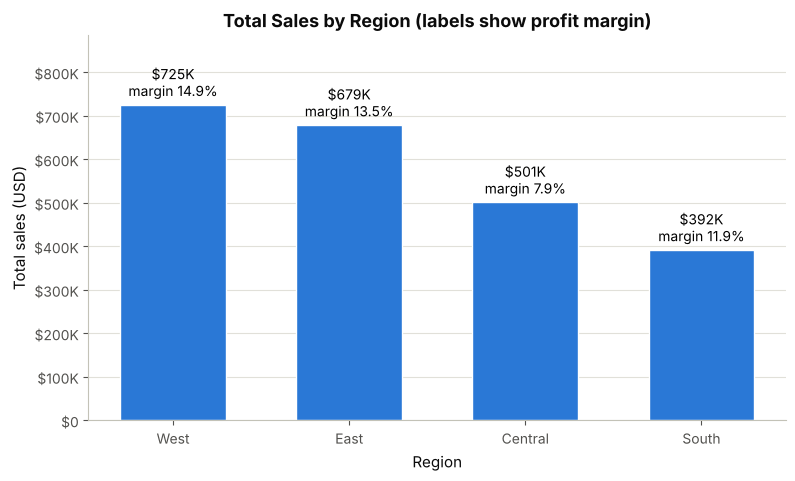

,Sales,Profit,Transactions,Orders,AOV,Customers,Margin_pct,Sales_share_pct
Segment,,,,,,,,
Consumer,"1,161,401.34","134,119.21",5191,2586,449.11,409,11.55,50.56
Corporate,"706,146.37","91,979.13",3020,1514,466.41,236,13.03,30.74
Home Office,"429,653.15","60,298.68",1783,909,472.67,148,14.03,18.70


Table saved -> outputs/summary_tables/segment_summary.csv
Chart saved -> outputs/charts/29_segment_sales_profit.png


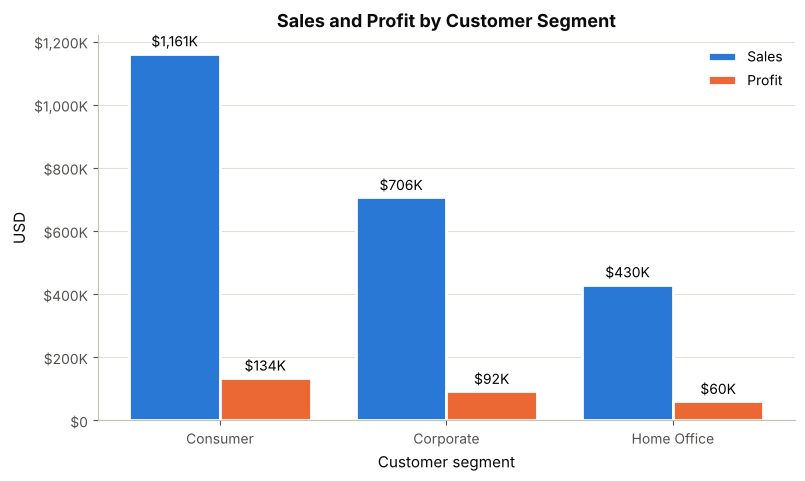

In [43]:
def group_summary(column):
    summary = df.groupby(column).agg(Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                                     Transactions=("Sales", "size"))
    if has("Order ID"):
        summary["Orders"] = df.groupby(column)["Order ID"].nunique()
        summary["AOV"] = summary["Sales"] / summary["Orders"]
    if has("Customer ID"):
        summary["Customers"] = df.groupby(column)["Customer ID"].nunique()
    summary["Margin_pct"] = summary["Profit"] / summary["Sales"] * 100
    summary["Sales_share_pct"] = summary["Sales"] / summary["Sales"].sum() * 100
    return summary.sort_values("Sales", ascending=False)


if has("Region"):
    region_summary = group_summary("Region")
    display(region_summary.round(2))
    save_table(region_summary.round(2), "region_summary")

    fig, ax = plt.subplots(figsize=(9, 5))
    bars = ax.bar(region_summary.index, region_summary["Sales"], color=BLUE, width=0.6, edgecolor="white")
    ax.bar_label(bars, labels=[f"${s / 1000:,.0f}K\nmargin {m:.1f}%"
                               for s, m in zip(region_summary["Sales"], region_summary["Margin_pct"])], padding=4)
    ax.set_title("Total Sales by Region (labels show profit margin)")
    ax.set_xlabel("Region")
    ax.set_ylabel("Total sales (USD)")
    ax.yaxis.set_major_formatter(MONEY_FMT)
    ax.set_ylim(0, region_summary["Sales"].max() * 1.22)
    save_chart(fig, "28_region_sales")
    plt.show()

if has("Segment"):
    segment_summary = group_summary("Segment")
    display(segment_summary.round(2))
    save_table(segment_summary.round(2), "segment_summary")

    fig, ax = plt.subplots(figsize=(9, 5))
    positions = np.arange(len(segment_summary))
    sales_bars = ax.bar(positions - 0.2, segment_summary["Sales"], width=0.4, color=BLUE, label="Sales",
                        edgecolor="white", linewidth=2)
    profit_bars = ax.bar(positions + 0.2, segment_summary["Profit"], width=0.4, color=ORANGE, label="Profit",
                         edgecolor="white", linewidth=2)
    ax.bar_label(sales_bars, labels=[f"${v / 1000:,.0f}K" for v in segment_summary["Sales"]], padding=3)
    ax.bar_label(profit_bars, labels=[f"${v / 1000:,.0f}K" for v in segment_summary["Profit"]], padding=3)
    ax.set_xticks(positions)
    ax.set_xticklabels(segment_summary.index)
    ax.set_title("Sales and Profit by Customer Segment")
    ax.set_xlabel("Customer segment")
    ax.set_ylabel("USD")
    ax.yaxis.set_major_formatter(MONEY_FMT)
    ax.legend()
    save_chart(fig, "29_segment_sales_profit")
    plt.show()

In [44]:
# Customer purchasing patterns
if has("Customer ID") and has("Order ID"):
    customer_summary = (df.groupby("Customer ID")
                          .agg(Orders=("Order ID", "nunique"), Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                               Units=("Quantity", "sum"))
                          .sort_values("Sales", ascending=False))
    if has("Customer Name"):
        customer_summary.insert(0, "Customer Name", df.groupby("Customer ID")["Customer Name"].first())
    if has("Segment"):
        customer_summary.insert(1, "Segment", df.groupby("Customer ID")["Segment"].first())

    print("Orders per customer:")
    display(customer_summary["Orders"].describe().to_frame().T.round(2))
    repeat_share = (customer_summary["Orders"] > 1).mean() * 100
    top_10pct = customer_summary.head(max(1, len(customer_summary) // 10))
    print(f"Customers with more than one order: {repeat_share:.1f}%")
    print(f"Top 10% of customers by sales generate {top_10pct['Sales'].sum() / total_sales:.1%} of total sales")
    print("Top 10 customers by recorded sales (sum of their transactions in this dataset, not lifetime value):")
    display(customer_summary.head(10).round(2))
    save_table(customer_summary.head(10).round(2), "top10_customers")

if has("Ship Mode") and has("Segment"):
    ship_mix = pd.crosstab(df["Segment"], df["Ship Mode"], normalize="index") * 100
    print("Ship-mode preference by segment (% of the segment's transactions):")
    display(ship_mix.round(1))
    save_table(ship_mix.round(2), "shipmode_by_segment")

Orders per customer:


,count,mean,std,min,25%,50%,75%,max
Orders,793.00,6.32,2.55,1.00,5.00,6.00,8.00,17.00


Customers with more than one order: 98.5%
Top 10% of customers by sales generate 30.6% of total sales
Top 10 customers by recorded sales (sum of their transactions in this dataset, not lifetime value):


,Customer Name,Segment,Orders,Sales,Profit,Units
Customer ID,,,,,,
SM-20320,Sean Miller,Home Office,5,"25,043.05","-1,980.74",50
TC-20980,Tamara Chand,Corporate,5,"19,052.22","8,981.32",42
RB-19360,Raymond Buch,Consumer,6,"15,117.34","6,976.10",71
TA-21385,Tom Ashbrook,Home Office,4,"14,595.62","4,703.79",36
AB-10105,Adrian Barton,Consumer,10,"14,473.57","5,444.81",73
KL-16645,Ken Lonsdale,Consumer,12,"14,175.23",806.86,113
SC-20095,Sanjit Chand,Consumer,9,"14,142.33","5,757.41",87
HL-15040,Hunter Lopez,Consumer,6,"12,873.30","5,622.43",50
SE-20110,Sanjit Engle,Consumer,11,"12,209.44","2,650.68",78


Table saved -> outputs/summary_tables/top10_customers.csv
Ship-mode preference by segment (% of the segment's transactions):


Ship Mode,First Class,Same Day,Second Class,Standard Class
Segment,,,,
Consumer,14.80,6.10,19.60,59.40
Corporate,16.10,3.80,20.20,60.00
Home Office,15.90,6.30,17.70,60.10


Table saved -> outputs/summary_tables/shipmode_by_segment.csv


**Result in this run**
- **West:** highest sales ($725,458, 31.6%) and highest margin (14.9%).
- **Central:** third in sales but the **lowest margin (7.9%)**.
- **Consumer:** 50.6% of sales and 46.8% of profit.
- **Home Office:** smallest segment but the highest margin (14.0%).
- **Repeat buying:**
  - **98.5%** of the 793 customers ordered more than once (median 6 orders in 4 years).
  - The top 10% of customers generate **30.6% of sales**.
- **Top customer** Sean Miller ($25,043 sales) produced a **loss of $1,981** → a high-spending customer is not necessarily a profitable one.
- Ship-mode preferences are almost identical across segments (about 60% Standard Class).

**Real-world use**
- Companies rank customers by profit, not only sales, before deciding who gets loyalty discounts.

## Section 17 — Discount and Profitability Patterns

,Transactions,Sales,Profit,Mean_row_margin_pct,Loss_rows_pct,Overall_margin_pct
Discount Band,,,,,,
0%,4798,"1,087,908.47","320,987.60",34.02,0.00,29.51
1-20%,3803,"846,522.24","100,785.47",17.44,13.75,11.91
21-40%,460,"234,137.90","-35,817.47",-16.69,90.22,-15.30
Above 40%,933,"128,632.25","-99,558.59",-108.90,100.00,-77.40


Table saved -> outputs/summary_tables/discount_band_summary.csv


Chart saved -> outputs/charts/30_discount_band_profitability.png


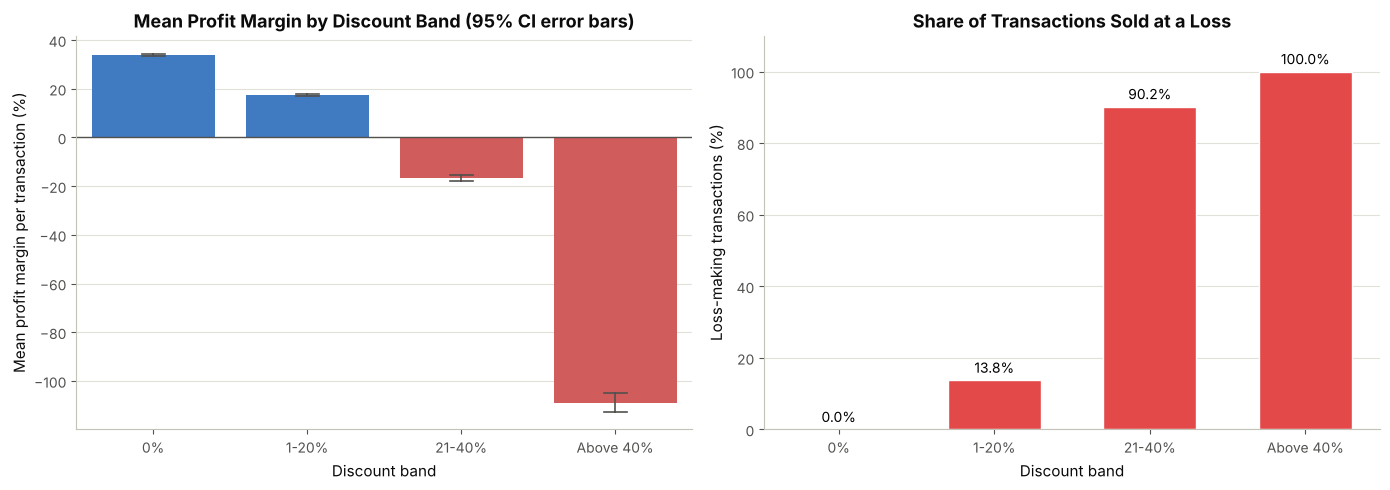

In [45]:
discount_summary = (df.groupby("Discount Band", observed=True)
                      .agg(Transactions=("Sales", "size"), Sales=("Sales", "sum"), Profit=("Profit", "sum"),
                           Mean_row_margin_pct=("Profit Margin (%)", "mean"), Loss_rows_pct=("Is Loss", "mean")))
discount_summary["Overall_margin_pct"] = discount_summary["Profit"] / discount_summary["Sales"] * 100
discount_summary["Loss_rows_pct"] *= 100
display(discount_summary.round(2))
save_table(discount_summary.round(2), "discount_band_summary")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
band_colors = {band: (BLUE if margin >= 0 else RED)
               for band, margin in discount_summary["Mean_row_margin_pct"].items()}
sns.barplot(data=df, x="Discount Band", y="Profit Margin (%)", estimator="mean", errorbar=("ci", 95),
            hue="Discount Band", palette=band_colors, legend=False, dodge=False, capsize=0.15,
            err_kws={"color": INK_2, "linewidth": 1.2}, ax=axes[0])
axes[0].axhline(0, color=INK_2, linewidth=1)
axes[0].set_title("Mean Profit Margin by Discount Band (95% CI error bars)")
axes[0].set_xlabel("Discount band")
axes[0].set_ylabel("Mean profit margin per transaction (%)")

bars = axes[1].bar(discount_summary.index.astype(str), discount_summary["Loss_rows_pct"], color=RED,
                   width=0.6, edgecolor="white")
axes[1].bar_label(bars, labels=[f"{v:.1f}%" for v in discount_summary["Loss_rows_pct"]], padding=3)
axes[1].set_title("Share of Transactions Sold at a Loss")
axes[1].set_xlabel("Discount band")
axes[1].set_ylabel("Loss-making transactions (%)")
axes[1].set_ylim(0, 110)
fig.tight_layout()
save_chart(fig, "30_discount_band_profitability")
plt.show()

Chart saved -> outputs/charts/31_subcategory_discount_vs_margin.png


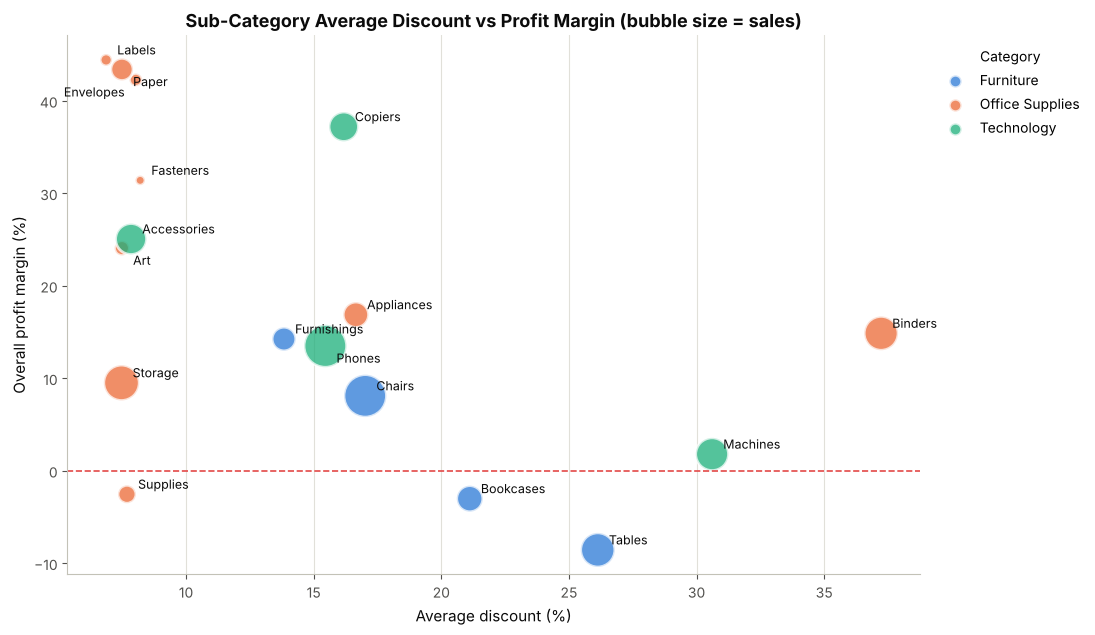

Pearson correlation across the 17 sub-categories (average discount vs margin): -0.52


In [46]:
if has("Sub-Category"):
    fig, ax = plt.subplots(figsize=(11, 7))
    for cat in CATEGORY_ORDER:
        part = sub_summary[sub_summary["Category"] == cat]
        ax.scatter(part["Avg_Discount"] * 100, part["Margin_pct"], s=part["Sales"] / sub_summary["Sales"].max() * 900 + 40,
                   color=CATEGORY_COLORS[cat], alpha=0.75, edgecolor="white", linewidth=2, label=cat)
    # Label every bubble; nudge a label to another side when a neighbour is too close
    x_span = sub_summary["Avg_Discount"].max() * 100 - sub_summary["Avg_Discount"].min() * 100
    y_span = sub_summary["Margin_pct"].max() - sub_summary["Margin_pct"].min()
    placed = []
    candidate_offsets = [((8, 4), "left"), ((8, -12), "left"), ((-8, 4), "right"), ((-8, -12), "right")]
    for _, row in sub_summary.sort_values("Margin_pct", ascending=False).iterrows():
        x, y = row["Avg_Discount"] * 100, row["Margin_pct"]
        for (dx, dy), align in candidate_offsets:
            spot = (x / x_span + dx / 400, y / y_span + dy / 300)
            if all(abs(spot[0] - px) > 0.09 or abs(spot[1] - py) > 0.035 for px, py in placed):
                break
        placed.append(spot)
        ax.annotate(row["Sub-Category"], (x, y), xytext=(dx, dy), textcoords="offset points",
                    ha=align, fontsize=9, color=INK)
    ax.axhline(0, color=RED, linewidth=1.2, linestyle="--")
    ax.set_title("Sub-Category Average Discount vs Profit Margin (bubble size = sales)")
    ax.set_xlabel("Average discount (%)")
    ax.set_ylabel("Overall profit margin (%)")
    ax.grid(axis="both")
    legend = ax.legend(title="Category", bbox_to_anchor=(1.01, 1), loc="upper left")
    for handle in getattr(legend, "legend_handles", None) or legend.legendHandles:
        handle.set_sizes([80])
    save_chart(fig, "31_subcategory_discount_vs_margin")
    plt.show()

    r_sub = np.corrcoef(sub_summary["Avg_Discount"], sub_summary["Margin_pct"])[0, 1]
    print(f"Pearson correlation across the {len(sub_summary)} sub-categories "
          f"(average discount vs margin): {r_sub:.2f}")

**Result in this run**

| Discount band | Transactions | Overall margin | Loss-making rows |
|---|---|---|---|
| 0% | 4,798 | 29.5% | 0.0% |
| 1–20% | 3,803 | 11.9% | 13.8% |
| 21–40% | 460 | −15.3% | 90.2% |
| Above 40% | 933 | −77.4% | 100% |

- Discounts above 20% apply to **1,393 rows (13.9%)** and lost **$135,376** combined — equal to 47% of the total profit the business kept.
- **Sub-category level:** average discount vs margin r = **−0.52**.
  - Tables, Machines and Bookcases combine high discounts with low or negative margins.
  - Binders is the exception: it has the highest average discount (37%) but still a 14.9% margin.
- **Caution:** this is an association. The data cannot show whether discounts *cause* losses, or whether already-unprofitable products (for example, slow stock being cleared) are the ones that get discounted.

## Section 18 — Final Business Insights: Results Table

- Answers the 10 business questions using values **computed from the data** in the cells above.
- The *Evidence* column names the chart or table to place next to each answer in the report.

In [47]:
def fmt_money(value):
    return f"-${abs(value):,.0f}" if value < 0 else f"${value:,.0f}"


cat_sales = category_summary["Total_Sales"]
cat_profit = category_summary["Total_Profit"]
top_month = monthly["Sales"].idxmax()
answers = []

answers.append(["1. Which category has the highest total sales?",
                f"{cat_sales.idxmax()} ({fmt_money(cat_sales.max())}, {category_summary.loc[cat_sales.idxmax(), 'Sales_Share_pct']:.1f}% of sales)",
                "01_category_sales.png; category_summary.csv",
                f"Sales are fairly evenly spread: each category holds "
                f"{category_summary['Sales_Share_pct'].min():.0f}-{category_summary['Sales_Share_pct'].max():.0f}% of sales.",
                "Keep stock depth and supplier terms strongest for this category."])
answers.append(["2. Which category has the highest total profit?",
                f"{cat_profit.idxmax()} ({fmt_money(cat_profit.max())}, margin {category_summary.loc[cat_profit.idxmax(), 'Profit_Margin_pct']:.1f}%); "
                f"lowest: {cat_profit.idxmin()} ({fmt_money(cat_profit.min())}, margin {category_summary.loc[cat_profit.idxmin(), 'Profit_Margin_pct']:.1f}%)",
                "02_category_profit.png",
                "The sales leader and the profit leader are not necessarily the same category.",
                "Review pricing and discounting in the lowest-margin category before growing its volume."])
if has("Product Name"):
    answers.append(["3. Which products have negative aggregate profit?",
                    f"{len(loss_products)} of {len(product_summary)} products ({len(loss_products) / len(product_summary):.1%}); "
                    f"combined loss {fmt_money(loss_products['Total_Profit'].sum())}; worst: {bottom_profit.iloc[0]['Product Name'][:45]}",
                    "26_bottom10_products_profit.png; loss_making_products.csv",
                    "Losses are concentrated in a limited set of products.",
                    "Re-price, cap discounts on, or delist repeat loss-makers after checking their costs."])
answers.append(["4. Which month has the highest recorded sales?",
                f"{top_month} ({fmt_money(monthly['Sales'].max())}); strongest calendar month on average: "
                f"{month_labels[int(np.argmax(month_mean.values))]}",
                "23_monthly_sales_trend.png; 24_yearly_and_seasonal_sales.png",
                "Sales show a repeating seasonal pattern within each year.",
                "Build inventory and staffing ahead of the peak months."])
if has("Region"):
    answers.append(["5. Which region contributes the most sales?",
                    f"{region_summary.index[0]} ({fmt_money(region_summary['Sales'].iloc[0])}, "
                    f"{region_summary['Sales_share_pct'].iloc[0]:.1f}%); lowest margin: "
                    f"{region_summary['Margin_pct'].idxmin()} ({region_summary['Margin_pct'].min():.1f}%)",
                    "28_region_sales.png; region_summary.csv",
                    f"Regions differ in both volume and profitability; {region_summary['Margin_pct'].idxmin()} "
                    f"keeps the least profit per dollar of sales.",
                    "Investigate discounting and product mix in the lowest-margin region."])
if has("Segment"):
    answers.append(["6. Which customer segment contributes the most sales and profit?",
                    f"Sales: {segment_summary['Sales'].idxmax()} ({fmt_money(segment_summary['Sales'].max())}); "
                    f"Profit: {segment_summary['Profit'].idxmax()} ({fmt_money(segment_summary['Profit'].max())}); "
                    f"margins range {segment_summary['Margin_pct'].min():.1f}%-{segment_summary['Margin_pct'].max():.1f}%",
                    "29_segment_sales_profit.png; 09_segment_sales_pie.png",
                    "The largest segment drives volume; margins are similar across segments.",
                    "Prioritise retention offers for the largest segment; grow smaller segments where margins hold."])
answers.append(["7. Is discount associated with profit?",
                f"Pearson r = {pearson.loc['Discount', 'Profit']:.2f}, Spearman rho = {spearman.loc['Discount', 'Profit']:.2f}; "
                f"loss-making rows: {discount_summary['Loss_rows_pct'].iloc[0]:.1f}% at 0% discount vs "
                f"{discount_summary['Loss_rows_pct'].iloc[-1]:.1f}% above 40%",
                "12_discount_vs_profit.png; 30_discount_band_profitability.png",
                "Higher discounts are associated with lower profit (association, not proof of cause).",
                "Test a discount cap (for example 20%) on the categories with the largest discount losses."])
answers.append(["8. How are quantity and sales related?",
                f"Pearson r = {pearson.loc['Quantity', 'Sales']:.2f}, Spearman rho = {spearman.loc['Quantity', 'Sales']:.2f}",
                "11_sales_vs_quantity.png",
                "More units go with higher sales, but the product's price matters far more than quantity.",
                "Use bundle/volume offers mainly on high-price items where they move revenue."])
if has("Region"):
    weakest = reg_cat_profit.stack().sort_values().head(3)
    answers.append(["9. Which region-category combinations perform poorly?",
                    "; ".join(f"{r} - {c} ({fmt_money(v)}, margin {reg_cat_margin.loc[r, c]:.1f}%)"
                              for (r, c), v in weakest.items()),
                    "19_region_category_heatmap.png; 20_subcategory_region_heatmap.png",
                    "A few region-category cells drag down overall profit.",
                    "Audit pricing, discounting and shipping cost for these combinations first."])
answers.append(["10. What business actions are supported by the evidence?",
                "Cap heavy discounts; fix or drop loss-making sub-categories/products; plan stock for peak months; "
                "focus on the lowest-margin region",
                "Sections 13-17",
                "Profitability problems are linked to discount levels and specific products/regions, not to low demand.",
                "Pilot the changes in one region and compare margins before a full rollout."])

results_table = pd.DataFrame(answers, columns=["Business question", "Actual result", "Evidence",
                                               "Interpretation", "Recommendation"])
with pd.option_context("display.max_colwidth", None):
    display(results_table)
save_table(results_table, "business_questions_results", index=False)

,Business question,Actual result,Evidence,Interpretation,Recommendation
0,1. Which category has the highest total sales?,"Technology ($836,154, 36.4% of sales)",01_category_sales.png; category_summary.csv,Sales are fairly evenly spread: each category holds 31-36% of sales.,Keep stock depth and supplier terms strongest for this category.
1,2. Which category has the highest total profit?,"Technology ($145,455, margin 17.4%); lowest: Furniture ($18,451, margin 2.5%)",02_category_profit.png,The sales leader and the profit leader are not necessarily the same category.,Review pricing and discounting in the lowest-margin category before growing its volume.
2,3. Which products have negative aggregate profit?,"301 of 1850 products (16.3%); combined loss -$77,068; worst: Cubify CubeX 3D Printer Double Head Print",26_bottom10_products_profit.png; loss_making_products.csv,Losses are concentrated in a limited set of products.,"Re-price, cap discounts on, or delist repeat loss-makers after checking their costs."
3,4. Which month has the highest recorded sales?,"2017-11 ($118,448); strongest calendar month on average: Nov",23_monthly_sales_trend.png; 24_yearly_and_seasonal_sales.png,Sales show a repeating seasonal pattern within each year.,Build inventory and staffing ahead of the peak months.
4,5. Which region contributes the most sales?,"West ($725,458, 31.6%); lowest margin: Central (7.9%)",28_region_sales.png; region_summary.csv,Regions differ in both volume and profitability; Central keeps the least profit per dollar of sales.,Investigate discounting and product mix in the lowest-margin region.
5,6. Which customer segment contributes the most sales and profit?,"Sales: Consumer ($1,161,401); Profit: Consumer ($134,119); margins range 11.5%-14.0%",29_segment_sales_profit.png; 09_segment_sales_pie.png,The largest segment drives volume; margins are similar across segments.,Prioritise retention offers for the largest segment; grow smaller segments where margins hold.
6,7. Is discount associated with profit?,"Pearson r = -0.22, Spearman rho = -0.54; loss-making rows: 0.0% at 0% discount vs 100.0% above 40%",12_discount_vs_profit.png; 30_discount_band_profitability.png,"Higher discounts are associated with lower profit (association, not proof of cause).",Test a discount cap (for example 20%) on the categories with the largest discount losses.
7,8. How are quantity and sales related?,"Pearson r = 0.20, Spearman rho = 0.33",11_sales_vs_quantity.png,"More units go with higher sales, but the product's price matters far more than quantity.",Use bundle/volume offers mainly on high-price items where they move revenue.
8,9. Which region-category combinations perform poorly?,"Central - Furniture (-$2,871, margin -1.8%); East - Furniture ($3,046, margin 1.5%); South - Furniture ($6,771, margin 5.8%)",19_region_category_heatmap.png; 20_subcategory_region_heatmap.png,A few region-category cells drag down overall profit.,"Audit pricing, discounting and shipping cost for these combinations first."
9,10. What business actions are supported by the evidence?,Cap heavy discounts; fix or drop loss-making sub-categories/products; plan stock for peak months; focus on the lowest-margin region,Sections 13-17,"Profitability problems are linked to discount levels and specific products/regions, not to low demand.",Pilot the changes in one region and compare margins before a full rollout.


Table saved -> outputs/summary_tables/business_questions_results.csv


**What the code does**
- Every *Actual result* is built from variables calculated earlier (no number is typed by hand), so the table always matches your dataset.
- The *Interpretation* and *Recommendation* columns are observations and suggestions; they should be checked against the printed results — especially if you use a different dataset version.

## Section 19 — Conclusions and Recommendations

### Conclusions (from this dataset run)
- The business recorded **$2.30M** in sales and **$286K** profit (12.5% margin) over 2014–2017, with strong growth in 2016–2017.
- **Technology** leads in both sales and profit. **Furniture** sells nearly as much but keeps only a **2.5% margin**.
- **Discounting is the pattern most strongly associated with losses:**
  - Every transaction above 40% discount lost money.
  - Discounts above 20% lost $135K in total.
- **Losses are concentrated:**
  - in Tables, Bookcases and Supplies
  - in 301 specific products
  - in the Central region (lowest margin, 7.9%)
- **Demand is seasonal:** September and November–December are peak months; January–February are the weakest.
- Customers are loyal (98.5% repeat), but some of the biggest spenders are unprofitable.

### Recommendations (to test, not proven causes)
- **Discount policy:** pilot a 20% cap on standard discounts and track margin and volume before and after.
- **Tables and Bookcases:** review pricing, discounting and shipping cost; consider stopping deep discounts or dropping repeat loss-making items.
- **Central region:** audit discount practices and product mix; Central loses money in 7 of 17 sub-categories.
- **Inventory:** build stock ahead of September and the November–December peak; plan lighter stock for January–February.
- **Protect profit engines:** Copiers, Phones, Accessories and Paper deliver high margins — keep them well stocked and avoid discounting them.
- **Customers:** rank customers by profit, not only sales, before offering loyalty discounts.

### Limitations
- The data describes a **fictional** US retailer (2014–2017), not a live business.
- It has no product cost, shipping cost, marketing spend or returns data, so the *reasons* behind losses cannot be confirmed.
- Correlations show association, not causation.
- Cleaning decisions (for example, keeping the near-duplicate pair) slightly affect totals; all are documented in the cleaning log.

### Future enhancements
- Interactive dashboard (Streamlit or Power BI) for managers.
- Sales forecasting with time-series models.
- Customer segmentation with K-means clustering (RFM features).
- A controlled test (A/B) of discount caps to measure their real effect on profit.

## Section 20 — Save Cleaned Data, Summary Tables and Charts

- Saves the cleaned dataset and the cleaning log.
- Lists every exported file so you can check nothing is missing.
- In Colab, zips the whole project folder and downloads it.

In [48]:
cleaned_path = DATA_DIR / "cleaned_dataset.csv"
df.to_csv(cleaned_path, index=False, date_format="%Y-%m-%d")
save_table(cleaning_log_df, "cleaning_log", index=False)
print(f"Cleaned dataset saved -> data/cleaned_dataset.csv ({len(df):,} rows, {df.shape[1]} columns)")
print("Original dataset untouched ->", original_file.name)

charts = sorted(p.name for p in CHART_DIR.glob("*.png"))
tables = sorted(p.name for p in TABLE_DIR.glob("*.csv"))
print(f"\nCharts saved ({len(charts)}):")
print("\n".join("  " + c for c in charts))
print(f"\nSummary tables saved ({len(tables)}):")
print("\n".join("  " + t for t in tables))

if IN_COLAB:
    from google.colab import files
    archive = shutil.make_archive("/content/Retail_Sales_Analysis", "zip", PROJECT_DIR)
    files.download(archive)
    print("\nProject ZIP downloaded:", archive)

Table saved -> outputs/summary_tables/cleaning_log.csv
Cleaned dataset saved -> data/cleaned_dataset.csv (9,994 rows, 30 columns)
Original dataset untouched -> original_dataset.csv

Charts saved (31):
  01_category_sales.png
  02_category_profit.png
  03_sales_histogram.png
  04_profit_histogram_kde.png
  05_sales_boxplot.png
  06_profit_boxplot.png
  07_quantity_discount_distribution.png
  08_margin_density_by_category.png
  09_segment_sales_pie.png
  10_subcategory_frequency.png
  11_sales_vs_quantity.png
  12_discount_vs_profit.png
  13_profit_boxplot_by_category.png
  14_margin_violin_by_category.png
  15_segment_category_grouped_bar.png
  16_region_category_stacked_bar.png
  17_correlation_heatmap.png
  18_pair_plot.png
  19_region_category_heatmap.png
  20_subcategory_region_heatmap.png
  21_3d_scatter_optional.png
  22_pca_optional.png
  23_monthly_sales_trend.png
  24_yearly_and_seasonal_sales.png
  25_top10_products_sales.png
  26_bottom10_products_profit.png
  27_subcategory_

### Troubleshooting common errors

| Error | Cause | Fix |
|---|---|---|
| `UnicodeDecodeError` | CSV saved with Windows encoding | Already handled in Section 5 (tries cp1252/latin-1) |
| `FileNotFoundError` | Dataset not at `data/original_dataset.csv` | Rename/move the file, or re-upload in Colab |
| `ValueError: Required columns missing` | Your file uses different column names | Add the name to `COLUMN_ALIASES` in 7.1 |
| `KeyError: 'Region'` (or another column) | An optional column is absent | Optional sections check `has(column)`; re-run from Section 7 |
| `ModuleNotFoundError` | Library missing locally | `pip install -r requirements.txt` |
| Charts look empty or squashed | Notebook cells run out of order | *Runtime → Restart and run all* |
| Wrong months in trends | Dates parsed day-first | Check the verification printout in Section 7.3 |